# Projekt - fáza č. 3

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, TargetEncoder, StandardScaler,
                                   PowerTransformer, KBinsDiscretizer)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay, classification_report)
sns.set_theme(style="whitegrid")

## Príprava dát (toto je prevzaté z fázy 2)

Fáza 3 je v samostatnom notebooku, preto tu bez zmeny opakujeme čistenie a predspracovanie z fázy 2, aby bol notebook vykonateľný sám osebe:

* delenie 80/20 podľa jednotiek (`id_unit`), stratifikované na `Failure`, `random_state = 42` - rovnaké delenie ako vo fáze 2,
* čistenie a zlúčenie troch tabuliek (`make_numeric_frame`),
* pipeline z 2.3: one-hot, target encoding depa, orezanie 1,5 x IQR -> medián -> Yeo-Johnson -> StandardScaler a výber 16 atribútov z 2.2.

Všetko, čo sa učí z dát, je v `sklearn` pipeline, takže sa učí iba na trénovacej časti (aj vnútri krížovej validácie).

In [3]:
RANDOM_STATE = 42
TEST_SIZE = 0.20

def parse_dates(col):
    s = pd.Series(col).astype(str).str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d", "%Y/%m/%d", "%d %b %Y", "%m/%d/%Y, %H:%M:%S", "%Y-%m-%d %H:%M:%S"]:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

def clean_gateways(df):
    df = df.copy().rename(columns={"Lon": "lon", "idDepot": "id_deport", "macAddress": "mac_addr",
                                   "versionFirmware": "version_firmware", "Vendor": "vendor",
                                   "Technician": "technician"})
    if "gateway_id" not in df.columns:
        df = df.reset_index()
    df["gateway_id"] = pd.to_numeric(df["gateway_id"].astype(str).str.replace(r"\D", "", regex=True),
                                     errors="coerce").astype("Int64")
    df["id_unit"] = pd.to_numeric(df["id_unit"], errors="coerce").astype("Int64")
    for c in ["install_date", "seen_last"]:
        df[c] = parse_dates(df[c])
    return df

def clean_readings(df):
    df = df.copy().rename(columns={"currentMotor": "curr_motor", "oilTemperature": "oil_temp",
                                   "pressure_reservoir": "press_reserv", "rmsVibration": "rms_vibration",
                                   "Flowmeter": "flow", "dischargeDewpoint": "dis_dewp", "Failure": "fail"})
    df["id_unit"] = pd.to_numeric(df["id_unit"].astype(str).str.strip().str.replace(r"\D", "", regex=True),
                                  errors="coerce")
    bad = df["id_unit"] > 2000                      # chybne id v tvare 90000 + skutocne id
    df.loc[bad, "id_unit"] = df.loc[bad, "id_unit"] - 90000
    df["id_unit"] = df["id_unit"].astype("Int64")
    df["cycle_ts"] = parse_dates(df["cycle_ts"])
    for col, bad_value in {"oil_temp": -999, "curr_motor": 99, "dp_filter": 120}.items():
        df[col] = df[col].replace(bad_value, np.nan)   # chybove kody senzorov
    sensor_cols = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp"]
    agg = {c: "mean" for c in sensor_cols}
    agg["fail"] = "max"
    return df.groupby(["id_unit", "cycle_ts"], as_index=False).agg(agg)   # duplicity jednotka + den

def clean_units(df):
    df = df.copy().rename(columns={"idDepot": "id_deport", "year_commission": "y_commission",
                                   "serviceHours": "serv_hours", "serial_number": "serial_num"})
    class_map = {"1": 1, "l": 1, "light": 1, "2": 2, "med": 2, "n": 2, "normal": 2,
                 "3": 3, "h": 3, "heavy": 3}
    df["duty_class"] = df["duty_class"].astype(str).str.strip().str.lower().map(class_map).astype("Int64")
    df["overhaul_last"] = parse_dates(df["overhaul_last"])
    df["serv_hours"] = pd.to_numeric(df["serv_hours"], errors="coerce")
    return df

gateways_c = clean_gateways(pd.read_csv("./data/gateways.csv", sep=";", index_col=13))
units_c = clean_units(pd.read_csv("./data/units.csv", sep=",", index_col=5))
gateways_c = gateways_c.dropna(subset=["id_unit"]).drop_duplicates("id_unit").drop(columns="id_deport")
gateways_c["id_unit"] = gateways_c["id_unit"].astype("int64")

CAT_COLS = ["hardware_model", "version_firmware"]
DROP_COLS = ["gateway_id", "mac_addr", "ipv4", "serial_num", "install_date", "seen_last",
             "overhaul_last", "cycle_ts", "vendor", "technician"]

def make_numeric_frame(readings_raw):
    r = clean_readings(readings_raw)
    df = (r.merge(units_c, on="id_unit", how="left", validate="m:1")
           .merge(gateways_c, on="id_unit", how="left", validate="m:1"))
    assert len(df) == len(r), "merge zmenil pocet riadkov"
    t = df["cycle_ts"]
    df["days_since_install"] = (t - df["install_date"]).dt.days
    df["days_since_overhaul"] = (t - df["overhaul_last"]).dt.days
    df["unit_age_years"] = t.dt.year - df["y_commission"]
    df["cycle_month"] = t.dt.month
    df["cycle_dow"] = t.dt.dayofweek
    df["cycle_doy"] = t.dt.dayofyear
    df["seen_before_install"] = (df["seen_last"] < df["install_date"]).astype(int)
    for c in ["dp_filter", "rms_vibration"]:
        df[c + "_missing"] = df[c].isna().astype(int)
    df = df.drop(columns=DROP_COLS)
    for c in df.columns:
        if str(df[c].dtype) in ("Int64", "Float64"):
            df[c] = df[c].astype("float64")
    return df

def prepare_data(readings_raw):
    df = make_numeric_frame(readings_raw)
    return df.drop(columns=["fail", "id_unit"]), df["fail"], df["id_unit"]

In [4]:
# spojite atributy (uprava v pipeline) a 16 atributov vybranych v 2.2
spojite = ["curr_motor", "dp_filter", "oil_temp", "press_reserv", "rms_vibration", "flow", "dis_dewp",
           "serv_hours", "signal_dbm", "lat", "lon", "days_since_install", "days_since_overhaul",
           "unit_age_years"]
selected_final = ["dp_filter_missing", "rms_vibration_missing", "duty_class", "dp_filter", "serv_hours",
                  "curr_motor", "rms_vibration", "dis_dewp", "press_reserv", "version_firmware_v3.4.1",
                  "y_commission", "oil_temp", "flow", "version_firmware_v2.7.0", "lat", "id_deport"]

class OutlierClipper(BaseEstimator, TransformerMixin):
    # orezanie odlahlych hodnot na 1,5 x IQR; hranice sa ucia na train
    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        X = np.asarray(X, dtype=float)
        q25, q75 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        self.lo_, self.hi_ = q25 - 1.5 * (q75 - q25), q75 + 1.5 * (q75 - q25)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)

class ColumnSelector(BaseEstimator, TransformerMixin):
    # ponecha len vybrane stlpce
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        self.columns_ = list(self.columns)
        return self
    def transform(self, X):
        return X[self.columns]
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns, dtype=object)

def build_pipeline(vyber=selected_final):
    continuous_steps = Pipeline([
        ("clip", OutlierClipper()),
        ("impute", SimpleImputer(strategy="median")),
        ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scale", StandardScaler()),
    ])
    transform_all = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.05,
                                 sparse_output=False), CAT_COLS),
        ("depot", TargetEncoder(target_type="binary", smooth="auto", cv=5, shuffle=True, random_state=RANDOM_STATE), ["id_deport"]),
        ("continuous", continuous_steps, spojite),
    ], remainder="passthrough", verbose_feature_names_out=False)
    kroky = [("transform", transform_all)]
    if vyber is not None:                       # vyber=None ponecha vsetky atributy (pouzijeme pri kontrole uniku)
        kroky.append(("select", ColumnSelector(vyber)))
    return Pipeline(kroky).set_output(transform="pandas")

In [5]:
data = pd.read_csv("./data/readings.csv", sep="\t")
jednotka = data["id_unit"].str[1:].astype(int)
jednotka = jednotka.where(jednotka <= 2000, jednotka - 90000)

sgkf = StratifiedGroupKFold(n_splits=round(1 / TEST_SIZE), shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(data, data["Failure"], groups=jednotka))

train_X, train_y, train_groups = prepare_data(data.iloc[train_idx])
test_X, test_y, test_groups = prepare_data(data.iloc[test_idx])

assert set(train_groups).isdisjoint(test_groups)
for nazov, X_, y_, g_ in [("train", train_X, train_y, train_groups), ("test", test_X, test_y, test_groups)]:
    print(nazov, "- riadky:", len(X_), "- jednotky:", g_.nunique(), "- podiel fail=1:", round(y_.mean(), 4))

train - riadky: 11016 - jednotky: 1597 - podiel fail=1: 0.1198
test - riadky: 2756 - jednotky: 402 - podiel fail=1: 0.1187


Dostali sme rovnaké množiny ako vo fáze 2 (11 016 trénovacích a 2 756 testovacích riadkov, podiel porúch asi 12 %). Testovaciu množinu odkladáme a použijeme ju až na záverečné overenie; všetky rozhodnutia robíme iba na trénovacej množine pomocou krížovej validácie.

## 3.1 Jednoduchý klasifikátor na základe závislosti v dátach

### Implementácia ID3

ID3 stavia strom zhora nadol. V každom uzle vyberie atribút s najvyšším **informačným ziskom**, teda ten, ktorý najviac zníži entropiu cieľovej premennej.

Uzol sa rozvetví podľa hodnôt atribútu a ten sa na ceste od koreňa už nepoužije. Vetvenie končí, keď je uzol čistý, nie sú atribúty alebo žiadny nemá kladný zisk. List predikuje väčšinovú triedu.

**Rozhodnutia pri implementácii**

* Spojité atribúty delíme na **kvartily** (Q1 až Q4, `KBinsDiscretizer`). Hranice sa učia len na trénovacej časti v rámci pipeline.
* Hĺbku počítame **vrátane koreňa**, ako v zadaní (`max_depth = 2` = koreň + jedna úroveň).
* Voliteľné parametre: `max_depth`, `min_samples_split` a `class_weight="balanced"`; bez nich ide o čistý ID3.
* Trieda má rozhranie `scikit-learn` (`fit`, `predict`, `predict_proba`), takže ide použiť v `Pipeline`.

In [6]:
class ID3Classifier(ClassifierMixin, BaseEstimator):
    # ID3 pre binarny ciel (0/1) a kategoricke atributy
    # hlbka sa pocita vratane korena

    def __init__(self, max_depth=None, min_samples_split=2, class_weight=None):
        self.max_depth = max_depth        # None = bez obmedzenia
        self.min_samples_split = min_samples_split      # mensi uzol sa uz nedeli
        self.class_weight = class_weight          # None alebo "balanced"

    @staticmethod
    def _entropy(w0, w1):
        h = 0.0
        for w in (w0, w1):
            if w > 0:
                p = w / (w0 + w1)
                h -= p * np.log2(p)
        return h

    def _gain(self, col, y, w):
        # informacny zisk atributu = entropia uzla - vazena entropia vetiev
        w1 = w[y == 1].sum(); w0 = w.sum() - w1
        zvysok = 0.0
        for v in np.unique(col):
            m = col == v
            v1 = w[m & (y == 1)].sum(); v0 = w[m].sum() - v1
            zvysok += (v0 + v1) / (w0 + w1) * self._entropy(v0, v1)
        return self._entropy(w0, w1) - zvysok

    def fit(self, X, y):
        self.feature_names_in_ = np.asarray(X.columns if hasattr(X, "columns")
                                            else [f"x{i}" for i in range(np.shape(X)[1])], dtype=object)
        X, y = np.asarray(X), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        if self.class_weight == "balanced":          # vaha triedy = n/(2pocet v triede)
            vahy_tried = len(y) / (2 * np.bincount(y, minlength=2))
        else:
            vahy_tried = np.ones(2)
        self.n_nodes_, self.n_leaves_, self.depth_ = 0, 0, 0
        self.tree_ = self._build(X, y, vahy_tried[y], list(range(X.shape[1])), depth=1)
        return self

    def _build(self, X, y, w, attrs, depth):
        w1 = w[y == 1].sum(); w0 = w.sum() - w1
        node = {"n": len(y), "n1": int(y.sum()), "p1": w1 / (w0 + w1), "attr": None}
        self.n_nodes_ += 1
        self.depth_ = max(self.depth_, depth)

        koniec = (w0 == 0 or w1 == 0 or not attrs or len(y) < self.min_samples_split
                  or (self.max_depth is not None and depth >= self.max_depth))
        best_gain, best_attr = 1e-12, None
        if not koniec:
            for a in attrs:
                g = self._gain(X[:, a], y, w)
                if g > best_gain:
                    best_gain, best_attr = g, a
        if best_attr is None:                        # list
            self.n_leaves_ += 1
            return node

        node["attr"], node["gain"], node["children"] = best_attr, best_gain, {}
        zvysne = [a for a in attrs if a != best_attr]   # atribut sa na ceste pouzije len raz
        for v in np.unique(X[:, best_attr]):
            m = X[:, best_attr] == v
            node["children"][v] = self._build(X[m], y[m], w[m], zvysne, depth + 1)
        return node

    def predict_proba(self, X):
        X = np.asarray(X)
        p1 = np.empty(len(X))
        for i, row in enumerate(X):
            node = self.tree_
            while node["attr"] is not None:
                child = node["children"].get(row[node["attr"]])
                if child is None:
                    break
                node = child
            p1[i] = node["p1"]
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)


def vypis_strom(model, max_uroven=None, node=None, odsadenie="", bin_cols=(), ciel="porucha"):
    # textovy vypis pravidiel
    # pri binovanych atributoch (bin_cols) su hodnoty Q1...Q4
    node = model.tree_ if node is None else node
    if node["attr"] is None:
        return
    meno = model.feature_names_in_[node["attr"]]
    for v, child in sorted(node["children"].items()):
        if meno in bin_cols:
            hodnota = f"Q{int(v) + 1}"
        else:
            hodnota = f"{v:g}" if isinstance(v, (int, float, np.number)) else str(v)
        popis = f"{odsadenie}{meno} = {hodnota}  [n={child['n']}, {ciel}={child['n1'] / child['n']:.0%}"
        if child["attr"] is None:
            print(popis + f"] -> {ciel}={int(child['p1'] > 0.5)}")
        else:
            print(popis + "]")
            if max_uroven is None or len(odsadenie) // 4 + 2 < max_uroven:
                vypis_strom(model, max_uroven, child, odsadenie + "    ", bin_cols, ciel)

Atribúty s viac ako 5 rôznymi hodnotami binujeme na kvartily, ostatné (0/1 príznaky a `duty_class`) vstupujú do stromu priamo. Celý model je jedna pipeline: predspracovanie z fázy 2 -> binovanie -> ID3.

In [7]:
prep_ukazka = build_pipeline().fit_transform(train_X, train_y)
BIN_COLS = [c for c in selected_final if prep_ukazka[c].nunique() > 5]
print("binovane na kvartily:", BIN_COLS)
print("bez zmeny:", [c for c in selected_final if c not in BIN_COLS])

def id3_pipeline(**params):
    binner = ColumnTransformer(
        [("bin", KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile",
                                  quantile_method="averaged_inverted_cdf"), BIN_COLS)],
        remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([("prep", build_pipeline()), ("bin", binner), ("id3", ID3Classifier(**params))])

binovane na kvartily: ['dp_filter', 'serv_hours', 'curr_motor', 'rms_vibration', 'dis_dewp', 'press_reserv', 'y_commission', 'oil_temp', 'flow', 'lat', 'id_deport']
bez zmeny: ['dp_filter_missing', 'rms_vibration_missing', 'duty_class', 'version_firmware_v3.4.1', 'version_firmware_v2.7.0']


Najprv overíme, podľa čoho sa strom rozhoduje v koreni: informačný zisk každého atribútu na celej trénovacej množine.

entropia ciela v koreni: 0.5289


,dp_filter_missing,rms_vibration_missing,duty_class,dp_filter,version_firmware_v3.4.1,y_commission,serv_hours,rms_vibration,dis_dewp,curr_motor,press_reserv,id_deport,oil_temp,version_firmware_v2.7.0,flow,lat
informacny zisk,0.0328,0.0282,0.0171,0.0128,0.0119,0.011,0.0096,0.0057,0.0051,0.0049,0.0048,0.0046,0.0017,0.0016,0.0012,0.0


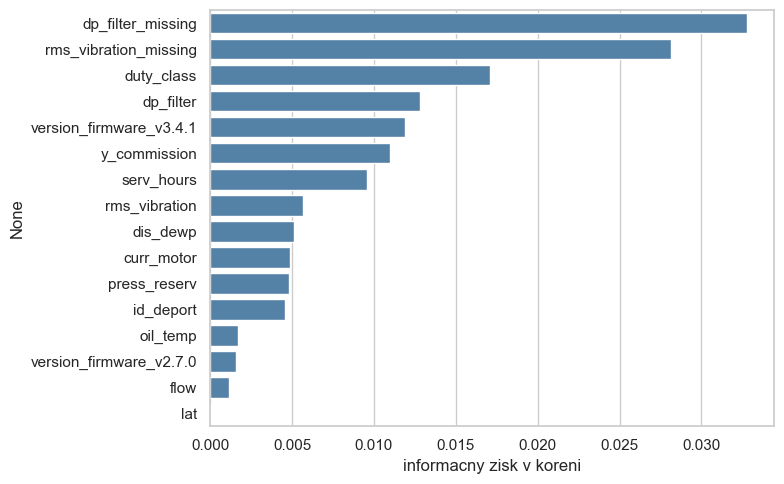

In [8]:
binovane = id3_pipeline()[:-1].fit_transform(train_X, train_y)
id3_pomocny = ID3Classifier()
zisk = pd.Series({c: id3_pomocny._gain(binovane[c].to_numpy(), train_y.to_numpy(), np.ones(len(train_y)))
                  for c in binovane.columns}).sort_values(ascending=False)
p = train_y.mean()
print("entropia ciela v koreni:", round(-(p * np.log2(p) + (1 - p) * np.log2(1 - p)), 4))

display(zisk.round(4).to_frame("informacny zisk").T)

plt.figure(figsize=(8, 5))
sns.barplot(x=zisk.values, y=zisk.index, color="steelblue")
plt.xlabel("informacny zisk v koreni"); plt.tight_layout(); plt.show()

Entropia cieľa v koreni je 0,529 bitu (asi 12 % porúch). Najviac ju znižujú príznaky chýbajúceho merania `dp_filter_missing` (0,033) a `rms_vibration_missing` (0,028), za nimi `duty_class` (0,017) a `dp_filter` (0,013). Poradie sa zhoduje s výberom atribútov z 2.2. Koreňom stromu bude `dp_filter_missing`.

Zisky sú v absolútnej hodnote malé: žiadny atribút sám poruchu neurčí, preto strom potrebuje viac úrovní.

In [9]:
id3_zaklad = id3_pipeline().fit(train_X, train_y)      # cisty ID3 bez obmedzeni
strom = id3_zaklad.named_steps["id3"]
print("hlbka (vratane korena):", strom.depth_, "| uzly:", strom.n_nodes_, "| listy:", strom.n_leaves_)
print("\nprve dve urovne pod korenom:")
vypis_strom(strom, max_uroven=3, bin_cols=BIN_COLS)

hlbka (vratane korena): 13 | uzly: 4192 | listy: 2908

prve dve urovne pod korenom:
dp_filter_missing = 0  [n=10610, porucha=10%]
    rms_vibration_missing = 0  [n=10229, porucha=9%]
    rms_vibration_missing = 1  [n=381, porucha=49%]
dp_filter_missing = 1  [n=406, porucha=57%]
    rms_vibration_missing = 0  [n=374, porucha=53%]
    rms_vibration_missing = 1  [n=32, porucha=97%]


Čistý ID3 bez obmedzení narástol do hĺbky 13 (požiadavka zadania na hĺbku aspoň 2 vrátane koreňa je splnená) a má 4 192 uzlov, z toho 2 908 listov. Na 11 016 trénovacích riadkov to vychádza na menej ako 4 riadky na list, čo je prvý signál, že si strom pamätá jednotlivé merania.

Prvé úrovne sú pritom zmysluplné: ak chýba `dp_filter`, podiel porúch je 57 % oproti 10 %, a ak chýbajú obe merania, až 97 % (32 riadkov). Platí predpoklad z fázy 2, že hodnota chýba skôr, než porucha nastane.

### Vyhodnotenie ID3

Porúch je asi 12 %, takže model "vždy bez poruchy" má accuracy 88 %, no je nepoužiteľný. Rozhodujeme preto podľa **recall**, **precision**, **F1**, **balanced accuracy**, **ROC-AUC** a **PR-AUC** - accuracy uvádzame len na porovnanie.

Hodnotíme 5-násobnou CV na trénovacej množine delenou podľa `id_unit` (`StratifiedGroupKFold`), pričom sa celá pipeline v každom foldu učí nanovo.

In [10]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "balanced accuracy": "balanced_accuracy", "precision": "precision",
           "recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc", "PR-AUC": "average_precision"}

def cv_vysledky(model):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")        # precision = 0/0, ked model v niektorom kroku nepredikuje ziadnu poruchu
        s = cross_validate(model, train_X, train_y, groups=train_groups, cv=cv, scoring=SCORING,
                           return_train_score=True, n_jobs=-1)
    return pd.DataFrame({"train": {m: s["train_" + m].mean() for m in SCORING},
                         "validacia": {m: s["test_" + m].mean() for m in SCORING},
                         "validacia std": {m: s["test_" + m].std() for m in SCORING}})

def metriky(model, X, y):
    pred, proba = model.predict(X), model.predict_proba(X)[:, 1]
    return pd.Series({"accuracy": accuracy_score(y, pred), "balanced accuracy": balanced_accuracy_score(y, pred),
                      "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                      "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, proba),
                      "PR-AUC": average_precision_score(y, proba)})

vys_zaklad = cv_vysledky(id3_pipeline())
vys_zaklad["rozdiel"] = vys_zaklad["train"] - vys_zaklad["validacia"]
display(vys_zaklad.round(3))

,train,validacia,validacia std,rozdiel
accuracy,0.983,0.820,0.002,0.163
balanced accuracy,0.959,0.593,0.012,0.366
precision,0.930,0.270,0.013,0.660
recall,0.927,0.295,0.028,0.633
F1,0.929,0.282,0.019,0.647
ROC-AUC,0.962,0.609,0.011,0.353
PR-AUC,0.879,0.172,0.007,0.707


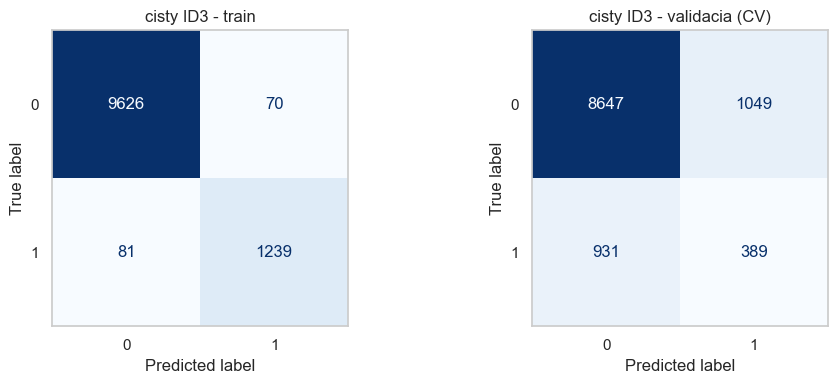

              precision    recall  f1-score   support

 bez poruchy      0.903     0.892     0.897      9696
     porucha      0.271     0.295     0.282      1320

    accuracy                          0.820     11016
   macro avg      0.587     0.593     0.590     11016
weighted avg      0.827     0.820     0.824     11016



In [11]:
# matica zamien z validacnych casti 
# kazdy riadok je predikovany modelom, ktory ho pri uceni nevidel
pred_val = cross_val_predict(id3_pipeline(), train_X, train_y, groups=train_groups, cv=cv, n_jobs=-1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(train_y, id3_zaklad.predict(train_X), ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("cisty ID3 - train")
ConfusionMatrixDisplay.from_predictions(train_y, pred_val, ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title("cisty ID3 - validacia (CV)")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()
print(classification_report(train_y, pred_val, target_names=["bez poruchy", "porucha"], digits=3))

**Vyhodnotenie čistého ID3.** Na trénovacích častiach vyzerá model takmer dokonale (F1 0,929; ROC-AUC 0,962), na validačných je slabý:

* zachytí iba 29,5 % porúch (recall) a z hlásených porúch je skutočných 27,0 % (precision), F1 = 0,282
* accuracy 0,820 je nižšia než 0,880, ktoré by dosiahol model bez jedinej hlásenej poruchy, takže o kvalite nič nehovorí
* ROC-AUC 0,609 je len o málo lepšie než náhodné zoradenie (0,5) a PR-AUC je len 0,172

Výsledky sú medzi piatimi časťami stabilné (smerodajná odchýlka F1 0,019), takže nejde o náhodu jedného delenia.

### Overfitting

**Má ID3 overfit?** Porovnávame skóre na trénovacích a validačných častiach krížovej validácie. Ak je model na dátach, ktoré videl, výrazne lepší než na nových, naučil sa šum a nie vzťahy. Zložitosť stromu riadime hĺbkou, preto pre každú hĺbku meriame obe skóre.

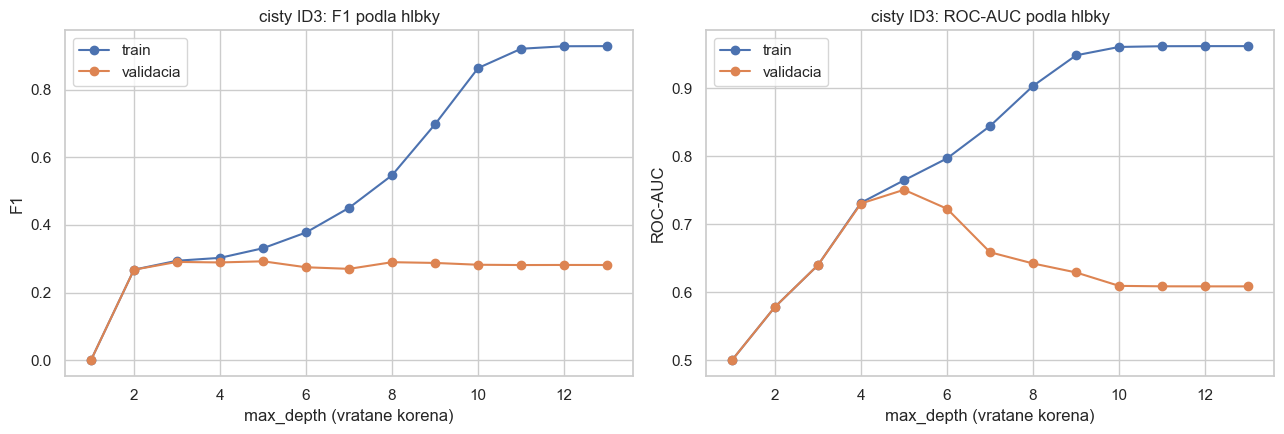

,F1 train,recall train,precision train,ROC-AUC train,F1 val,recall val,precision val,ROC-AUC val
max_depth,,,,,,,,
1,0.000,0.000,0.000,0.500,0.000,0.000,0.000,0.500
2,0.268,0.175,0.569,0.578,0.268,0.175,0.569,0.578
3,0.294,0.204,0.563,0.640,0.291,0.201,0.555,0.640
4,0.303,0.202,0.631,0.732,0.289,0.197,0.565,0.731
5,0.331,0.219,0.693,0.765,0.292,0.196,0.584,0.751
6,0.378,0.248,0.793,0.797,0.275,0.182,0.565,0.723
7,0.451,0.300,0.908,0.845,0.270,0.182,0.530,0.659
8,0.547,0.399,0.870,0.904,0.290,0.217,0.439,0.642
9,0.698,0.577,0.882,0.949,0.288,0.253,0.334,0.629


In [12]:
hlbky = list(range(1, 14))      # neobmedzeny strom ma hlbku 13, cize 13 = bez obmedzenia
riadky = []
for vahy in [None, "balanced"]:
    for h in hlbky:
        v = cv_vysledky(id3_pipeline(max_depth=h, class_weight=vahy))
        riadky.append({"class_weight": str(vahy), "max_depth": h,
                       **{f"{m} train": v.loc[m, "train"] for m in ["F1", "recall", "precision", "ROC-AUC"]},
                       **{f"{m} val": v.loc[m, "validacia"] for m in ["F1", "recall", "precision", "ROC-AUC"]}})
krivka = pd.DataFrame(riadky)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
k = krivka[krivka["class_weight"] == "None"]
for a, m in zip(ax, ["F1", "ROC-AUC"]):
    a.plot(k["max_depth"], k[f"{m} train"], marker="o", label="train")
    a.plot(k["max_depth"], k[f"{m} val"], marker="o", label="validacia")
    a.set_title(f"cisty ID3: {m} podla hlbky"); a.set_xlabel("max_depth (vratane korena)")
    a.set_ylabel(m); a.legend()
plt.tight_layout(); plt.show()
display(k.set_index("max_depth").drop(columns="class_weight").round(3))


**Áno, čistý ID3 má overfit.**

* Do hĺbky 5 idú obe krivky spolu (ROC-AUC 0,765 na train a 0,751 na validácii).
* Od hĺbky 6 trénovacie skóre ďalej rastie (F1 až 0,93, ROC-AUC 0,96), no validačné ROC-AUC klesá z 0,751 na 0,609 a validačné F1 sa drží okolo 0,28. Každá ďalšia úroveň teda pridáva pravidlá, ktoré platia len pre trénovacie riadky.
* Pri neobmedzenom strome je rozdiel medzi train a validáciou 0,65 v F1 a 0,35 v ROC-AUC.

Opačný problém vidno pri hĺbke 1 a 2: model je príliš jednoduchý (ROC-AUC 0,50 a 0,58), čo je underfit. Vhodná zložitosť je teda niekde okolo hĺbky 5.

**Riešenie.** Používame dve úpravy:

1. **Predčasné zastavenie (pre-pruning)** - obmedzíme hĺbku (`max_depth`) a najmenší uzol, ktorý sa ešte smie deliť (`min_samples_split`). Strom tak nemôže vytvárať listy pre jednotlivé riadky.
2. **Váhy tried** (`class_weight="balanced"`) - samotné orezanie overfit odstráni, ale plytký strom s väčšinovým hlasovaním takmer nikdy nepredikuje poruchu. Váhy vyrovnajú obe triedy v entropii aj v listoch.

Porovnanie oboch variantov pri rovnakej hĺbke:

In [13]:
por = krivka[krivka["max_depth"].isin([3, 4, 5, 6])].pivot(index="max_depth", columns="class_weight",
                                                       values=["recall val", "precision val", "F1 val", "ROC-AUC val"])
display(por.round(3))

recall val          precision val          F1 val           \
class_weight       None balanced          None balanced   None balanced   
max_depth                                                                 
3                 0.201    0.317         0.555    0.531  0.291    0.396   
4                 0.197    0.739         0.565    0.202  0.289    0.318   
5                 0.196    0.652         0.584    0.251  0.292    0.362   
6                 0.182    0.552         0.565    0.268  0.275    0.361   

             ROC-AUC val           
class_weight        None balanced  
max_depth                          
3                  0.640    0.640  
4                  0.731    0.731  
5                  0.751    0.752  
6                  0.723    0.718

Váhy takmer nemenia zoradenie pozorovaní (ROC-AUC), menia rozhodnutie v listoch: pri hĺbke 5 stúpne recall z 0,196 na 0,652 a F1 z 0,292 na 0,362, precision klesne z 0,584 na 0,251. Pri prediktívnej údržbe je prehliadnutá porucha drahšia než falošný poplach, preto ďalej používame `class_weight="balanced"`.

Zostáva zvoliť `max_depth` a `min_samples_split`

In [14]:
riadky = []
for h in [3, 4, 5, 6, 7, 8, 10]:
    for mss in [2, 100, 200, 400]:
        v = cv_vysledky(id3_pipeline(max_depth=h, min_samples_split=mss, class_weight="balanced"))
        riadky.append({"max_depth": h, "min_samples_split": mss,
                       "ROC-AUC train": v.loc["ROC-AUC", "train"], "ROC-AUC val": v.loc["ROC-AUC", "validacia"],
                       "F1 train": v.loc["F1", "train"], "F1 val": v.loc["F1", "validacia"],
                       "recall val": v.loc["recall", "validacia"]})
mriezka = pd.DataFrame(riadky)
mriezka["rozdiel ROC-AUC"] = mriezka["ROC-AUC train"] - mriezka["ROC-AUC val"]
mriezka["rozdiel F1"] = mriezka["F1 train"] - mriezka["F1 val"]

# bez overfitu: train a validacia sa lisia najviac o 0,02, spomedzi nich najlepsie validacne ROC-AUC
bez_overfitu = mriezka[(mriezka["rozdiel ROC-AUC"] <= 0.02) & (mriezka["rozdiel F1"] <= 0.02)]
najlepsi = bez_overfitu.sort_values("ROC-AUC val", ascending=False, kind="stable").iloc[0]
display(mriezka.sort_values("ROC-AUC val", ascending=False).head(12).round(3))
print("vybrane nastavenie: max_depth =", int(najlepsi["max_depth"]), "| min_samples_split =", int(najlepsi["min_samples_split"]))


,max_depth,min_samples_split,ROC-AUC train,ROC-AUC val,F1 train,F1 val,recall val,rozdiel ROC-AUC,rozdiel F1
23,8,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
27,10,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
19,7,400,0.793,0.760,0.386,0.360,0.642,0.033,0.025
9,5,100,0.764,0.760,0.369,0.365,0.659,0.005,0.004
10,5,200,0.764,0.760,0.369,0.365,0.659,0.005,0.004
13,6,100,0.790,0.759,0.397,0.378,0.602,0.030,0.019
11,5,400,0.763,0.759,0.369,0.365,0.659,0.004,0.004
14,6,200,0.789,0.759,0.397,0.378,0.602,0.030,0.019
15,6,400,0.786,0.758,0.394,0.371,0.592,0.027,0.022
22,8,200,0.808,0.755,0.393,0.361,0.656,0.054,0.032


vybrane nastavenie: max_depth = 5 | min_samples_split = 100


Validačné ROC-AUC 0,760 dosahuje viac nastavení. Stromy s hĺbkou 7 až 10 a `min_samples_split = 400` ho dosahujú s rozdielom 0,033 medzi train a validáciou, strom s hĺbkou 5 a `min_samples_split = 100` s rozdielom 0,005. Volíme preto jednoduchší: **`max_depth = 5`, `min_samples_split = 100`, `class_weight = "balanced"`**.

In [15]:
PARAMS = dict(max_depth=int(najlepsi["max_depth"]), min_samples_split=int(najlepsi["min_samples_split"]),
              class_weight="balanced")
vys_final = cv_vysledky(id3_pipeline(**PARAMS))
vys_final["rozdiel"] = vys_final["train"] - vys_final["validacia"]

porovnanie = pd.concat({"cisty ID3": vys_zaklad[["train", "validacia", "rozdiel"]],
                        "upraveny ID3": vys_final[["train", "validacia", "rozdiel"]]}, axis=1)
display(porovnanie.round(3))

cisty ID3                   upraveny ID3                  
                      train validacia rozdiel        train validacia rozdiel
accuracy              0.983     0.820   0.163        0.727     0.725   0.002
balanced accuracy     0.959     0.593   0.366        0.700     0.697   0.003
precision             0.930     0.270   0.660        0.256     0.253   0.003
recall                0.927     0.295   0.633        0.663     0.659   0.004
F1                    0.929     0.282   0.647        0.369     0.365   0.004
ROC-AUC               0.962     0.609   0.353        0.764     0.760   0.005
PR-AUC                0.879     0.172   0.707        0.381     0.364   0.016

**Záverečné overenie na testovacej množine.** Upravený ID3 učíme na celej trénovacej množine a prvýkrát ho použijeme na testovacej, ktorú model ani výber parametrov nevideli.

hlbka (vratane korena): 5 | uzly: 41 | listy: 29


,cisty ID3 - train,cisty ID3 - test,upraveny ID3 - train,upraveny ID3 - test
accuracy,0.986,0.830,0.715,0.717
balanced accuracy,0.966,0.618,0.700,0.723
precision,0.947,0.306,0.248,0.257
recall,0.939,0.339,0.680,0.731
F1,0.943,0.322,0.364,0.380
ROC-AUC,0.968,0.635,0.764,0.788
PR-AUC,0.901,0.194,0.388,0.418


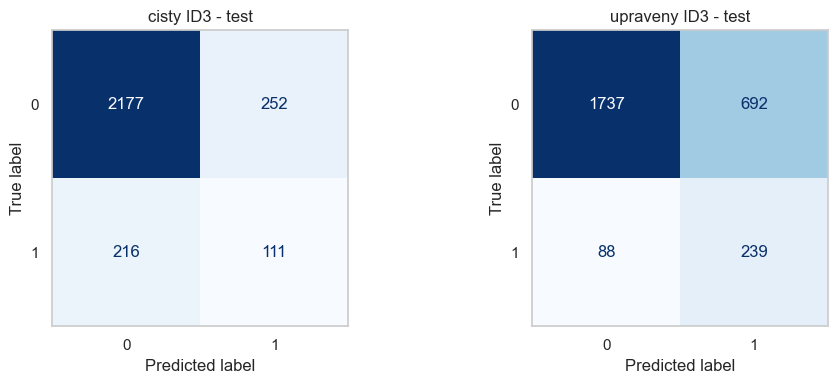

In [16]:
id3_final = id3_pipeline(**PARAMS).fit(train_X, train_y)
strom = id3_final.named_steps["id3"]
print("hlbka (vratane korena):", strom.depth_, "| uzly:", strom.n_nodes_, "| listy:", strom.n_leaves_)

tab = pd.DataFrame({"cisty ID3 - train": metriky(id3_zaklad, train_X, train_y),
                    "cisty ID3 - test": metriky(id3_zaklad, test_X, test_y),
                    "upraveny ID3 - train": metriky(id3_final, train_X, train_y),
                    "upraveny ID3 - test": metriky(id3_final, test_X, test_y)})
display(tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(test_y, id3_zaklad.predict(test_X), ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("cisty ID3 - test")
ConfusionMatrixDisplay.from_predictions(test_y, id3_final.predict(test_X), ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title("upraveny ID3 - test")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()

In [17]:
print("pravidla upraveneho ID3 (prve tri urovne pod korenom):")
vypis_strom(strom, max_uroven=4, bin_cols=BIN_COLS)

pravidla upraveneho ID3 (prve tri urovne pod korenom):
dp_filter_missing = 0  [n=10610, porucha=10%]
    rms_vibration_missing = 0  [n=10229, porucha=9%]
        duty_class = 1  [n=4040, porucha=14%]
        duty_class = 2  [n=3639, porucha=7%]
        duty_class = 3  [n=2550, porucha=4%]
    rms_vibration_missing = 1  [n=381, porucha=49%]
        serv_hours = Q1  [n=71, porucha=34%] -> porucha=1
        serv_hours = Q2  [n=86, porucha=41%] -> porucha=1
        serv_hours = Q3  [n=111, porucha=50%]
        serv_hours = Q4  [n=113, porucha=64%]
dp_filter_missing = 1  [n=406, porucha=57%]
    rms_vibration_missing = 0  [n=374, porucha=53%]
        y_commission = Q1  [n=93, porucha=69%] -> porucha=1
        y_commission = Q2  [n=91, porucha=51%] -> porucha=1
        y_commission = Q3  [n=70, porucha=50%] -> porucha=1
        y_commission = Q4  [n=120, porucha=46%]
    rms_vibration_missing = 1  [n=32, porucha=97%] -> porucha=1


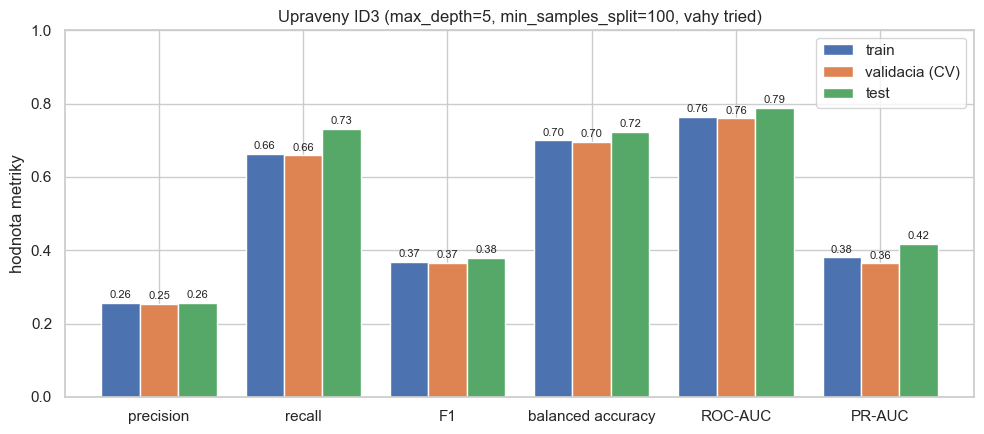

In [18]:
metriky_graf = ["precision", "recall", "F1", "balanced accuracy", "ROC-AUC", "PR-AUC"]
vysledky_graf = pd.DataFrame({
    "train": vys_final.loc[metriky_graf, "train"],
    "validacia (CV)": vys_final.loc[metriky_graf, "validacia"],
    "test": tab.loc[metriky_graf, "upraveny ID3 - test"],
})

ax = vysledky_graf.plot(kind="bar", figsize=(10, 4.5), width=0.8, edgecolor="white")
for kontajner in ax.containers:
    ax.bar_label(kontajner, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1)
ax.set_ylabel("hodnota metriky")
ax.set_title("Upraveny ID3 (max_depth=5, min_samples_split=100, vahy tried)")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

Pri váhach tried list hlási poruchu, ak je v ňom podiel porúch vyšší než v celých dátach (asi 12 %), preto aj list s 34 % porúch dáva `fail=1`.

### Záver k 3.1

| | čistý ID3 | upravený ID3 |
|---|---|---|
| nastavenie | bez obmedzení | `max_depth=5`, `min_samples_split=100`, `class_weight="balanced"` |
| veľkosť | hĺbka 13, 4 192 uzlov | hĺbka 5, 41 uzlov |
| F1 train / test | 0,943 / 0,322 | 0,364 / 0,380 |
| ROC-AUC train / test | 0,968 / 0,635 | 0,764 / 0,788 |
| recall train / test | 0,939 / 0,339 | 0,680 / 0,731 |

* Implementovali sme ID3 (entropia, informačný zisk, kvartily) a hodnotili ho metrikami pre nevyvážené triedy v CV delenej podľa jednotiek.
* Čistý ID3 silno overfituje (F1 0,943 na train, 0,322 na teste). Po obmedzení hĺbky a uzla je strom stokrát menší a train, validácia aj test sedia (F1 0,364 / 0,365 / 0,380), takže overfit je odstránený a nejde ani o underfit.

**Obmedzenie:** precision je 0,26 (tri zo štyroch hlásení sú falošné poplachy), čo je cena za recall 0,73 pri jednoduchom strome. V 3.2 porovnáme ID3 so `scikit-learn`.

## 3.2 Trénovanie a vyhodnotenie klasifikátorov strojového učenia

Random forest a logistickú regresiu porovnávame s ID3 z časti 3.1. Používame rovnaké predspracovanie a päť validačných foldov podľa `id_unit`.

Poruchy tvoria asi 12 % dát, preto nastavenia vyberáme podľa priemernej validačnej AP (average precision). Testovaciu množinu použijeme až po výbere nastavení.

### Stromový algoritmus - Random Forest

Random forest kombinuje predikcie 160 stromov. Každý strom sa učí na náhodnej vzorke dát s opakovaním a pri delení zvažuje náhodný výber atribútov.

Porovnávame rôzne hĺbky stromov a minimálne počty záznamov v liste. Váhami tried zohľadňujeme, že poruchy sú zriedkavé.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.tree import plot_tree
from IPython.display import Markdown

def sk_pipeline(model):
    return Pipeline([("prep", build_pipeline()), ("model", model)])

forest_name = "Random Forest"
logreg_name = "Logisticka regresia"
id3_name = "ID3 upraveny"

forest_candidates = {
    (depth, leaf): sk_pipeline(RandomForestClassifier(
        n_estimators=160,
        max_depth=depth,
        min_samples_leaf=leaf,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
    ))
    for depth, leaf in [(4, 40), (7, 40), (7, 15), (10, 15)]
}
forest_cv = {params: cv_vysledky(model) for params, model in forest_candidates.items()}
forest_table = pd.DataFrame([
    {"max_depth": depth, "min_samples_leaf": leaf,
     "AP trening": scores.loc["PR-AUC", "train"],
     "AP validacia": scores.loc["PR-AUC", "validacia"],
     "F1 validacia": scores.loc["F1", "validacia"]}
    for (depth, leaf), scores in forest_cv.items()
]).set_index(["max_depth", "min_samples_leaf"]).sort_values("AP validacia", ascending=False, kind="stable")
best_forest = forest_table.index[0]
final_forest = forest_candidates[best_forest]
display(forest_table.round(3))
print(f"Vybrany les: max_depth={best_forest[0]}, min_samples_leaf={best_forest[1]}")

AP trening  AP validacia  F1 validacia
max_depth min_samples_leaf                                        
10        15                     0.649         0.451         0.458
7         15                     0.560         0.449         0.443
          40                     0.531         0.448         0.435
4         40                     0.465         0.437         0.401

Vybrany les: max_depth=10, min_samples_leaf=15


### Nestromový algoritmus — logistická regresia

Logistická regresia vytvára lineárnu kombináciu predspracovaných atribútov a pomocou logistickej funkcie ju prevádza na skóre poruchy. Hodnota `C` riadi silu regularizácie (menšie `C` znamená silnejšiu regularizáciu). Pri trénovaní používame vyvážené váhy tried.

In [20]:
logreg_candidates = {
    c: sk_pipeline(LogisticRegression(C=c, class_weight="balanced", max_iter=2000))
    for c in [0.01, 0.1, 1, 10]
}
logreg_cv = {c: cv_vysledky(model) for c, model in logreg_candidates.items()}
logreg_table = pd.DataFrame([
    {"C": c, "AP trening": scores.loc["PR-AUC", "train"],
     "AP validacia": scores.loc["PR-AUC", "validacia"],
     "F1 validacia": scores.loc["F1", "validacia"]}
    for c, scores in logreg_cv.items()
]).set_index("C").sort_values("AP validacia", ascending=False, kind="stable")
best_c = logreg_table.index[0]
final_logreg = logreg_candidates[best_c]
display(logreg_table.round(3))
print(f"Vybrana logisticka regresia: C={best_c:g}")

,AP trening,AP validacia,F1 validacia
C,,,
0.10,0.488,0.487,0.415
1.00,0.486,0.486,0.419
10.00,0.486,0.486,0.419
0.01,0.474,0.473,0.398


Vybrana logisticka regresia: C=0.1


### Porovnanie s ID3

Uvádzame priemery na validačných foldoch a smerodajnú odchýlku AP naprieč foldmi. Rozdiely medzi trénovacím a validačným skóre ukazujú, ako lepšie model funguje na dátach, na ktorých sa učil. Do tabuľky zahŕňame aj čistý ID3, aby bolo vidieť vplyv jeho obmedzenia z časti 3.1.

In [21]:
vys_cv = {"ID3 cisty": vys_zaklad, id3_name: vys_final,
          forest_name: forest_cv[best_forest], logreg_name: logreg_cv[best_c]}
cv_tab = pd.DataFrame({name: scores["validacia"] for name, scores in vys_cv.items()})
cv_std = pd.DataFrame({
    name: {"AP - smerodajna odchylka validacie": scores.loc["PR-AUC", "validacia std"]}
    for name, scores in vys_cv.items()
})
cv_gap = pd.DataFrame({
    name: (scores["train"] - scores["validacia"]).loc[["F1", "ROC-AUC", "PR-AUC"]]
    for name, scores in vys_cv.items()
})
cv_gap.index = [f"Rozdiel trening - validacia ({metric})" for metric in cv_gap.index]
display(pd.concat([cv_tab.rename(index={"PR-AUC": "AP"}), cv_std, cv_gap]).round(3))

for model in (final_forest, final_logreg):
    model.fit(train_X, train_y)
test_modely = {"ID3 cisty": id3_zaklad, id3_name: id3_final,
               forest_name: final_forest, logreg_name: final_logreg}
test_tab = pd.DataFrame({name: metriky(model, test_X, test_y) for name, model in test_modely.items()})
print("Testovacia mnozina")
display(test_tab.rename(index={"PR-AUC": "AP"}).round(3))

,ID3 cisty,ID3 upraveny,Random Forest,Logisticka regresia
accuracy,0.820,0.725,0.845,0.764
balanced accuracy,0.593,0.697,0.716,0.735
precision,0.270,0.253,0.395,0.296
recall,0.295,0.659,0.548,0.699
F1,0.282,0.365,0.458,0.415
ROC-AUC,0.609,0.760,0.795,0.807
AP,0.172,0.364,0.451,0.487
AP - smerodajna odchylka validacie,0.007,0.030,0.028,0.036
Rozdiel trening - validacia (F1),0.647,0.004,0.125,-0.001
Rozdiel trening - validacia (ROC-AUC),0.353,0.005,0.129,0.003


Testovacia mnozina


,ID3 cisty,ID3 upraveny,Random Forest,Logisticka regresia
accuracy,0.830,0.717,0.841,0.765
balanced accuracy,0.618,0.723,0.741,0.755
precision,0.306,0.257,0.392,0.301
recall,0.339,0.731,0.609,0.743
F1,0.322,0.380,0.477,0.429
ROC-AUC,0.635,0.788,0.820,0.837
AP,0.194,0.418,0.505,0.520


### Vizualizácia natrénovaných pravidiel

Diagram ukazuje prvé tri úrovne prvého stromu v natrénovanom lese. Prahy sú v jednotkách po predspracovaní vstupov. Ľavá vetva zodpovedá splnenej podmienke v uzle. Zobrazený strom je jeden z prispievateľov k výslednému skóre, ktoré vzniká priemerovaním odhadov celého lesa.

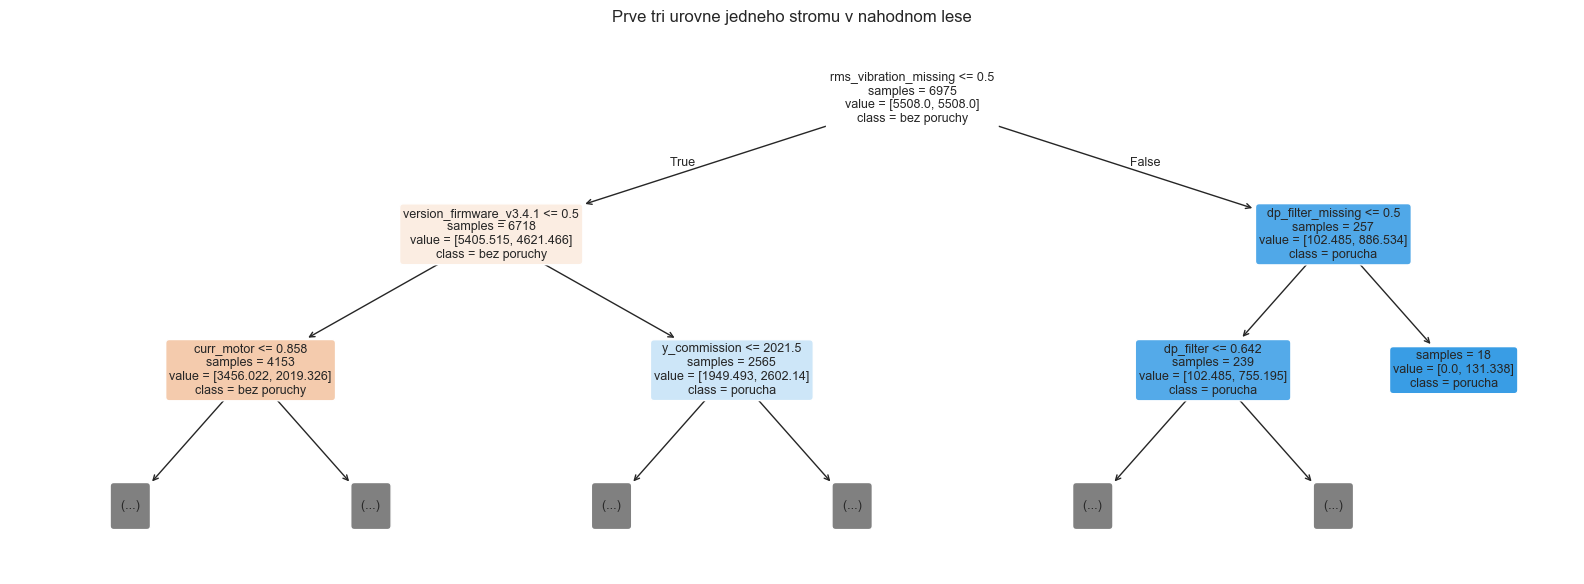

In [22]:
feature_names = final_forest.named_steps["prep"].get_feature_names_out()
first_tree = final_forest.named_steps["model"].estimators_[0]

fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(first_tree, feature_names=list(feature_names),
          class_names=["bez poruchy", "porucha"], max_depth=2,
          filled=True, rounded=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("Prve tri urovne jedneho stromu v nahodnom lese")
plt.tight_layout()
plt.show()

### Vyhodnotenie na testovacej množine

Matice zámen zobrazujú predvolené rozhodnutia modelov. Krivky ROC a precision–recall ukazujú, ako sa hodnotenie mení s prahom. Prerušovaná čiara v grafe precision–recall označuje podiel porúch v testovacej množine.

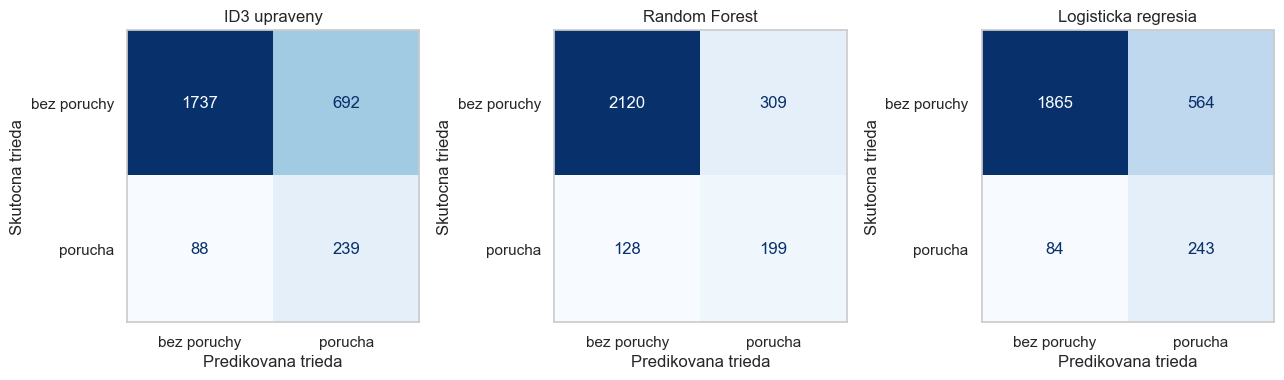

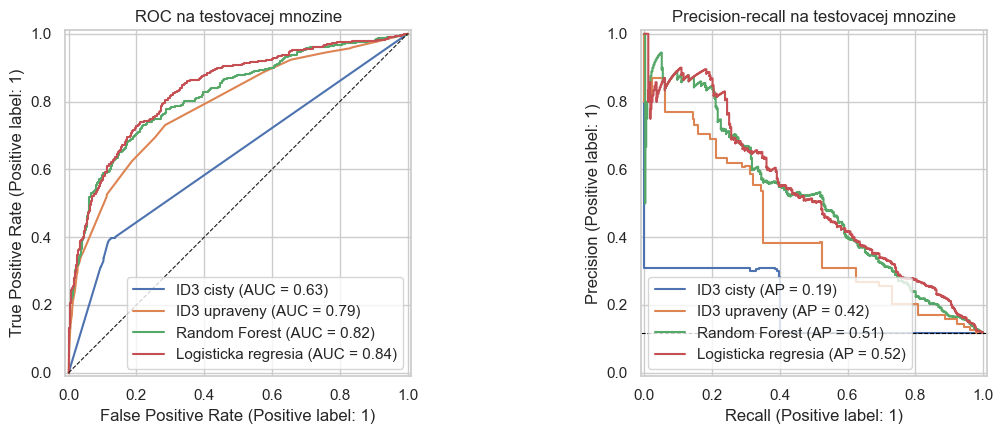

In [23]:
names = [id3_name, forest_name, logreg_name]
test_pred = {name: model.predict(test_X) for name, model in test_modely.items()}
test_proba = {name: model.predict_proba(test_X)[:, 1] for name, model in test_modely.items()}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, names):
    ConfusionMatrixDisplay.from_predictions(
        test_y, test_pred[name], display_labels=["bez poruchy", "porucha"],
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set(title=name, xlabel="Predikovana trieda", ylabel="Skutocna trieda")
    ax.grid(False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, scores in test_proba.items():
    RocCurveDisplay.from_predictions(test_y, scores, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(test_y, scores, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("ROC na testovacej mnozine")
axes[1].axhline(test_y.mean(), color="black", linestyle="--", linewidth=0.8)
axes[1].set_title("Precision-recall na testovacej mnozine")
plt.tight_layout()
plt.show()

### Záver k 3.2

In [24]:
modely = [id3_name, forest_name, logreg_name]

zhrnutie_32 = pd.DataFrame({
    "Validacna AP": cv_tab.loc["PR-AUC", modely],
    "Rozdiel AP (trening − validacia)": cv_gap.loc[
        "Rozdiel trening - validacia (PR-AUC)", modely
    ],
    "Testovacie F1": test_tab.loc["F1", modely],
    "Recall na teste": test_tab.loc["recall", modely],
    "Precision na teste": test_tab.loc["precision", modely],
})

display(zhrnutie_32.style.format({
    "Validacná AP": "{:.3f}",
    "Rozdiel AP (tréning − validacia)": "{:.3f}",
    "Testovacie F1": "{:.3f}",
    "Recall na teste": "{:.0%}",
    "Precision na teste": "{:.0%}",
}, decimal=","))

,Validacna AP,Rozdiel AP (trening − validacia),Testovacie F1,Recall na teste,Precision na teste
ID3 upraveny,"0,364417","0,016354","0,380",73%,26%
Random Forest,"0,450631","0,198728","0,477",61%,39%
Logisticka regresia,"0,486956","0,000667","0,429",74%,30%


- Logistická regresia mala najvyššiu validačnú AP (0,487). Random forest dosiahol 0,451 a upravený ID3 0,364.
- Random forest mal najvyššie F1 na teste (0,485). Rozdiel medzi tréningovou a validačnou AP (0,198) naznačuje preučenie.
- Logistická regresia zachytila viac porúch (74 % oproti 62 %). Random forest mal vyšší podiel správnych poplachov (40 % oproti 30 %).

Pri prediktívnej údržbe treba pri interpretácii výsledkov overiť, či príznaky chýbajúcich meraní poznáme už v okamihu predikcie.

## 3.3 Optimalizácia (hyperparameter tuning a ensemble)

Ladíme dva algoritmy z 3.2 (logistickú regresiu a rozhodovací strom) a pre stromový algoritmus skúšame aj ensemble (bagging, Random Forest, gradient boosting) a hlasovanie s logistickou regresiou. Všetko sa ladí krížovou validáciou na trénovacej množine delenou podľa `id_unit`, celá predspracovacia pipeline sa v každom foldu učí nanovo a testovaciu množinu nepoužívame, až na záverečné overenie.

Hlavná metrika je PR-AUC (`average_precision`), lebo je citlivá na vzácnu triedu (12 % porúch) a nezávisí od prahu. Spomedzi nastavení akceptujeme len tie, kde sa train a validácia líšia o najviac 0,03 PR-AUC (ochrana pred overfitom); najlepšie z nich vyberáme podľa validačnej PR-AUC.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, learning_curve
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              BaggingClassifier, VotingClassifier)
from sklearn.dummy import DummyClassifier
from scipy.stats import loguniform, randint

SCORING_T = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "F1": "f1", "recall": "recall"}
MAX_GAP = 0.05
NAJLEPSIE, VYSLEDKY, SPEC = {}, {}, {}

def strip(p):
    return {k.replace("model__", "", 1): v for k, v in p.items()}

def tune(nazov, model, params, n_iter=None):
    pipe = sk_pipeline(model)
    kw = dict(scoring=SCORING_T, refit=False, cv=cv, return_train_score=True, n_jobs=-1)
    s = (GridSearchCV(pipe, params, **kw) if n_iter is None else
         RandomizedSearchCV(pipe, params, n_iter=n_iter, random_state=RANDOM_STATE, **kw))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        s.fit(train_X, train_y, groups=train_groups)

    r = pd.DataFrame(s.cv_results_)
    r["gap PR-AUC"] = r["mean_train_PR-AUC"] - r["mean_test_PR-AUC"]
    ok = r[r["gap PR-AUC"] <= MAX_GAP]
    splnene = len(ok)
    if ok.empty:
        print(f"VAROVANIE: {nazov}: ziadne nastavenie nesplna gap <= {MAX_GAP}, beriem najmensi gap")
        ok = r.nsmallest(1, "gap PR-AUC")
    best = ok.sort_values("mean_test_PR-AUC", ascending=False).iloc[0]

    NAJLEPSIE[nazov], VYSLEDKY[nazov], SPEC[nazov] = best["params"], r, (model, params, n_iter)
    cols = ["mean_test_PR-AUC", "std_test_PR-AUC", "mean_train_PR-AUC", "gap PR-AUC",
            "mean_test_ROC-AUC", "mean_test_F1", "mean_test_recall"]
    print(f"{nazov}: vyskusanych {len(r)}, splna gap <= {MAX_GAP}: {splnene}")
    display(r.sort_values("mean_test_PR-AUC", ascending=False).head(5)[["params"] + cols].round(3))
    print("vybrane:", best["params"])
    return r

### A) Ladenie hyperparametrov

**Logistická regresia.** Ladíme silu regularizácie `C` a typ penalizácie (`l1_ratio`: 0 = L2, 1 = L1). Solver `saga` zvláda L1 aj L2.

In [26]:
for solver in ["lbfgs", "saga"]:
    m = sk_pipeline(LogisticRegression(solver=solver, C=1, class_weight="balanced", max_iter=5000))
    print(solver, round(cv_vysledky(m).loc["PR-AUC", "validacia"], 3))

lbfgs 0.486
saga 0.405


In [27]:
tune("logreg", LogisticRegression(solver="lbfgs", class_weight="balanced", max_iter=3000),
     {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]})

logreg: vyskusanych 6, splna gap <= 0.05: 6


,params,mean_test_PR-AUC,std_test_PR-AUC,mean_train_PR-AUC,gap PR-AUC,mean_test_ROC-AUC,mean_test_F1,mean_test_recall
2,{'model__C': 0.1},0.487,0.036,0.488,0.001,0.807,0.415,0.699
3,{'model__C': 0.3},0.487,0.036,0.487,0.000,0.808,0.417,0.695
1,{'model__C': 0.03},0.486,0.036,0.487,0.001,0.806,0.408,0.703
4,{'model__C': 1},0.486,0.036,0.486,0.000,0.808,0.419,0.695
5,{'model__C': 3},0.486,0.036,0.486,0.000,0.808,0.419,0.694


vybrane: {'model__C': 0.1}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__C,params,split0_test_PR-AUC,split1_test_PR-AUC,split2_test_PR-AUC,split3_test_PR-AUC,...,std_test_recall,rank_test_recall,split0_train_recall,split1_train_recall,split2_train_recall,split3_train_recall,split4_train_recall,mean_train_recall,std_train_recall,gap PR-AUC
0,1.003607,0.309374,0.088682,0.028994,0.01,{'model__C': 0.01},0.414263,0.477346,0.483672,0.520678,...,0.022706,1,0.716856,0.707386,0.719165,0.715232,0.719962,0.715720,0.004491,0.001121
1,1.061370,0.251763,0.107677,0.010401,0.03,{'model__C': 0.03},0.427217,0.497017,0.500281,0.535263,...,0.020490,2,0.706439,0.695076,0.704934,0.707663,0.702933,0.703409,0.004456,0.000720
2,1.235031,0.404089,0.078030,0.009308,0.10,{'model__C': 0.1},0.429581,0.498022,0.501992,0.536468,...,0.018843,3,0.704545,0.693182,0.701139,0.694418,0.702933,0.699243,0.004590,0.000667
3,1.015896,0.150067,0.082855,0.027783,0.30,{'model__C': 0.3},0.430434,0.496321,0.501856,0.536796,...,0.018867,4,0.704545,0.691288,0.701139,0.697256,0.702933,0.699432,0.004741,0.000233
4,0.976832,0.073279,0.067703,0.012618,1.00,{'model__C': 1},0.430562,0.495642,0.500690,0.536491,...,0.017478,5,0.706439,0.689394,0.703036,0.696310,0.702933,0.699623,0.006077,0.000297
5,0.919189,0.053502,0.044293,0.004249,3.00,{'model__C': 3},0.430537,0.495624,0.500668,0.536354,...,0.016777,6,0.706439,0.689394,0.703036,0.695364,0.702933,0.699433,0.006191,0.000312


### B) Ensemble pre stromový algoritmus

Ensemble znižuje rozptyl jedného stromu (bagging, Random Forest) alebo postupne opravuje jeho chyby (gradient boosting). Pri každom ensemble ladíme parametre, ktoré riadia zložitosť (hĺbka, minimálny list, počet stromov, miera učenia), a obmedzenie na rozdiel train − validácia platí rovnako ako pri jednom strome.

In [28]:
tune("random forest",
     RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=1),
     {"model__n_estimators": [300], "model__max_depth": [3, 4, 5, 6, 8],
      "model__min_samples_leaf": randint(40, 250), "model__max_features": ["sqrt", 0.5, 0.8],
      "model__max_samples": [0.3, 0.5, 0.7]}, n_iter=20)

tune("hist gradient boosting",
     HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False, random_state=RANDOM_STATE),
     {"model__learning_rate": loguniform(0.02, 0.2), "model__max_iter": [100, 150, 200],
      "model__max_depth": [2, 3], "model__max_leaf_nodes": randint(6, 20),
      "model__min_samples_leaf": randint(80, 300), "model__l2_regularization": loguniform(0.01, 10)}, n_iter=20)

random forest: vyskusanych 20, splna gap <= 0.05: 18


,params,mean_test_PR-AUC,std_test_PR-AUC,mean_train_PR-AUC,gap PR-AUC,mean_test_ROC-AUC,mean_test_F1,mean_test_recall
19,"{'model__max_depth': 6, 'model__max_features':...",0.447,0.029,0.492,0.045,0.791,0.421,0.636
3,"{'model__max_depth': 8, 'model__max_features':...",0.442,0.029,0.483,0.041,0.793,0.432,0.622
10,"{'model__max_depth': 8, 'model__max_features':...",0.439,0.026,0.504,0.065,0.794,0.441,0.610
12,"{'model__max_depth': 3, 'model__max_features':...",0.424,0.030,0.439,0.016,0.770,0.384,0.641
0,"{'model__max_depth': 6, 'model__max_features':...",0.398,0.024,0.449,0.051,0.776,0.399,0.661


vybrane: {'model__max_depth': 6, 'model__max_features': 0.5, 'model__max_samples': 0.7, 'model__min_samples_leaf': 87, 'model__n_estimators': 300}
hist gradient boosting: vyskusanych 20, splna gap <= 0.05: 16


,params,mean_test_PR-AUC,std_test_PR-AUC,mean_train_PR-AUC,gap PR-AUC,mean_test_ROC-AUC,mean_test_F1,mean_test_recall
18,{'model__l2_regularization': 0.129555172406621...,0.477,0.035,0.523,0.046,0.800,0.427,0.674
0,{'model__l2_regularization': 0.132929189431621...,0.475,0.034,0.521,0.047,0.799,0.428,0.672
4,{'model__l2_regularization': 0.074763120622523...,0.475,0.033,0.545,0.070,0.796,0.424,0.661
16,{'model__l2_regularization': 1.538230804027899...,0.475,0.033,0.529,0.054,0.799,0.427,0.664
10,{'model__l2_regularization': 0.042055711870072...,0.474,0.033,0.513,0.039,0.798,0.425,0.663


vybrane: {'model__l2_regularization': np.float64(0.12955517240662176), 'model__learning_rate': np.float64(0.09329776676652111), 'model__max_depth': 2, 'model__max_iter': 200, 'model__max_leaf_nodes': 17, 'model__min_samples_leaf': 183}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__l2_regularization,param_model__learning_rate,param_model__max_depth,param_model__max_iter,param_model__max_leaf_nodes,param_model__min_samples_leaf,...,std_test_recall,rank_test_recall,split0_train_recall,split1_train_recall,split2_train_recall,split3_train_recall,split4_train_recall,mean_train_recall,std_train_recall,gap PR-AUC
0,0.550703,0.033247,0.096006,0.003945,0.132929,0.178544,2,100,10,182,...,0.014638,2,0.723485,0.723485,0.738140,0.734153,0.735099,0.730873,0.006174,0.046701
1,0.580569,0.022648,0.130624,0.034970,0.217520,0.025177,2,100,9,183,...,0.022840,19,0.657197,0.630682,0.641366,0.638600,0.641438,0.641857,0.008617,0.010179
2,0.790015,0.125109,0.155183,0.036323,1.331122,0.020971,3,150,11,209,...,0.022588,16,0.679924,0.676136,0.680266,0.686850,0.676443,0.679924,0.003861,0.026086
3,0.851634,0.061804,0.123438,0.008573,0.035114,0.030509,3,150,11,168,...,0.018891,11,0.709280,0.700758,0.694497,0.702933,0.701041,0.701702,0.004737,0.039474
4,0.852304,0.059017,0.149384,0.024241,0.074763,0.081824,3,200,19,269,...,0.024312,5,0.757576,0.741477,0.750474,0.746452,0.757805,0.750757,0.006339,0.070485
5,0.590382,0.044923,0.099191,0.004974,2.267399,0.031674,2,100,8,130,...,0.013400,17,0.658144,0.639205,0.634725,0.650899,0.629139,0.642422,0.010631,0.019305
6,0.688982,0.034213,0.127813,0.023739,1.098810,0.056432,3,100,17,93,...,0.020415,9,0.712121,0.714962,0.702087,0.718070,0.712394,0.711927,0.005367,0.058631
7,0.679159,0.092711,0.119400,0.022248,2.661902,0.040331,2,150,9,171,...,0.015806,13,0.683712,0.677083,0.675522,0.686850,0.681173,0.680868,0.004168,0.023075
8,0.796478,0.093446,0.133085,0.007545,0.209150,0.026489,2,200,8,285,...,0.021709,12,0.685606,0.668561,0.674573,0.672658,0.666982,0.673676,0.006560,0.020184
9,0.717520,0.054842,0.127966,0.007544,0.148998,0.030427,3,150,19,213,...,0.020325,14,0.706439,0.697917,0.689753,0.704825,0.699149,0.699617,0.005900,0.036508


**Hlasovanie (soft voting).** Spriemeruje pravdepodobnosti poruchy z naladenej logistickej regresie, Random Forestu a boostingu, takže spája lineárny a nelineárny model. Stacking sme nepoužili, lebo jeho vnútorná krížová validácia nerešpektuje `id_unit` a metamodel by sa učil z optimistických predikcií.

In [ ]:
def zostav(nazov, model):
    return sk_pipeline(model).set_params(**NAJLEPSIE[nazov])

lr_t = clone(SPEC["logreg"][0]).set_params(**strip(NAJLEPSIE["logreg"]))
rf_t  = RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE,
                               n_jobs=1).set_params(**strip(NAJLEPSIE["random forest"]))
hgb_t = HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                       random_state=RANDOM_STATE).set_params(**strip(NAJLEPSIE["hist gradient boosting"]))
voting = VotingClassifier([("lr", lr_t), ("rf", rf_t), ("hgb", hgb_t)], voting="soft", n_jobs=1)

### Ladenie bez underfitu

Každý bod v grafe je jedno vyskúšané nastavenie. Pod diagonálou sú nastavenia, ktoré si pamätajú trénovacie dáta (overfit); nastavenia vľavo dole sú príliš jednoduché (underfit). Vybrané nastavenia ležia blízko diagonály a vysoko nad nastaveniami s nízkym skóre.

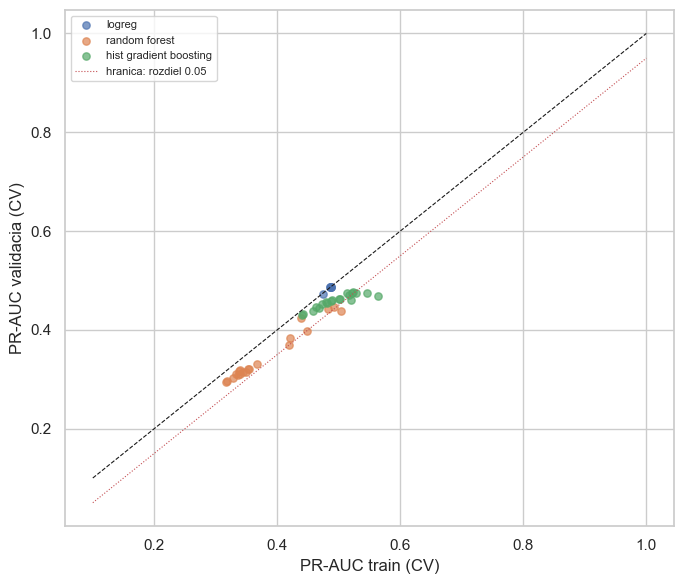

In [30]:
plt.figure(figsize=(7, 6))
for n, r in VYSLEDKY.items():
    plt.scatter(r["mean_train_PR-AUC"], r["mean_test_PR-AUC"], label=n, alpha=0.7, s=28)
lim = [0.1, 1.0]
plt.plot(lim, lim, "k--", lw=0.8)
plt.plot(lim, [l - MAX_GAP for l in lim], "r:", lw=0.8, label=f"hranica: rozdiel {MAX_GAP}")
plt.xlabel("PR-AUC train (CV)"); plt.ylabel("PR-AUC validacia (CV)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### C) Porovnanie v krížovej validácii

Všetky modely hodnotíme tou istou 5-násobnou krížovou validáciou delenou podľa `id_unit` (rovnaké foldy ako v 3.1 a 3.2). Ako spodnú hranicu pridávame model, ktorý vždy predikuje priemernú pravdepodobnosť poruchy (`DummyClassifier`); model, ktorý ho nepredbehne, je underfit. Víťaza určíme takto: akceptujeme modely s rozdielom train − validácia najviac 0,03 a spomedzi tých, ktorých PR-AUC je v rámci jednej smerodajnej odchýlky od najlepšieho, berieme najjednoduchší.

In [31]:
kandidati = {
    "dummy (prior)": sk_pipeline(DummyClassifier(strategy="prior")),
    "logreg (3.2)": final_logreg,
    "logreg (ladeny)": zostav("logreg", SPEC["logreg"][0]),
    "ID3 upraveny": id3_pipeline(**PARAMS),
    "random forest (3.2)": final_forest,
    "random forest (ladeny)": zostav("random forest", SPEC["random forest"][0]),
    "hist gradient boosting": zostav("hist gradient boosting", SPEC["hist gradient boosting"][0]),
    "voting (LR + RF + HGB)": sk_pipeline(voting),
}
zlozitost = list(kandidati)

def riadok(pipe):
    v = cv_vysledky(pipe)
    return pd.Series({"PR-AUC val": v.loc["PR-AUC", "validacia"], "PR-AUC std": v.loc["PR-AUC", "validacia std"],
                      "ROC-AUC val": v.loc["ROC-AUC", "validacia"], "F1 val": v.loc["F1", "validacia"],
                      "recall val": v.loc["recall", "validacia"], "precision val": v.loc["precision", "validacia"],
                      "gap PR-AUC": v.loc["PR-AUC", "train"] - v.loc["PR-AUC", "validacia"],
                      "gap ROC-AUC": v.loc["ROC-AUC", "train"] - v.loc["ROC-AUC", "validacia"]})

cmp = pd.DataFrame({n: riadok(p) for n, p in kandidati.items()}).T
display(cmp.sort_values("PR-AUC val", ascending=False).round(3))

ok = cmp.drop(index="dummy (prior)")
ok = ok.drop(index=[n for n in ok.index if "(3.2)" in n])
ok = ok[ok["gap PR-AUC"] <= MAX_GAP]
najv = ok["PR-AUC val"].idxmax()
dost = ok[ok["PR-AUC val"] >= ok.loc[najv, "PR-AUC val"] - ok.loc[najv, "PR-AUC std"]]
FINAL_NAME = sorted(dost.index, key=zlozitost.index)[0]
print("najlepsi PR-AUC:", najv, "| vybrany (najjednoduchsi v rozsahu 1 std):", FINAL_NAME)
final_pipe = kandidati[FINAL_NAME]

,PR-AUC val,PR-AUC std,ROC-AUC val,F1 val,recall val,precision val,gap PR-AUC,gap ROC-AUC
logreg (3.2),0.487,0.036,0.807,0.415,0.699,0.296,0.001,0.003
logreg (ladeny),0.487,0.036,0.807,0.415,0.699,0.296,0.001,0.003
voting (LR + RF + HGB),0.482,0.033,0.806,0.429,0.669,0.316,0.029,0.029
hist gradient boosting,0.477,0.035,0.800,0.427,0.674,0.313,0.046,0.045
random forest (3.2),0.451,0.028,0.795,0.458,0.548,0.395,0.199,0.129
random forest (ladeny),0.447,0.029,0.791,0.421,0.636,0.315,0.045,0.042
ID3 upraveny,0.364,0.030,0.760,0.365,0.659,0.253,0.016,0.005
dummy (prior),0.120,0.000,0.500,0.000,0.000,0.000,0.000,0.000


najlepsi PR-AUC: logreg (ladeny) | vybrany (najjednoduchsi v rozsahu 1 std): logreg (ladeny)


In [32]:
opak = []
for seed in range(5):
    cv_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=100 + seed)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        s = cross_validate(final_pipe, train_X, train_y, groups=train_groups, cv=cv_s,
                           scoring=SCORING_T, return_train_score=True, n_jobs=-1)
    opak.append({"seed": seed,
                 **{f"{m} train": s[f"train_{m}"].mean() for m in SCORING_T},
                 **{f"{m} val": s[f"test_{m}"].mean() for m in SCORING_T}})
opak = pd.DataFrame(opak).set_index("seed")
opak["gap PR-AUC"] = opak["PR-AUC train"] - opak["PR-AUC val"]
opak["gap ROC-AUC"] = opak["ROC-AUC train"] - opak["ROC-AUC val"]
display(opak.round(3))
print(opak.agg(["mean", "std"]).loc[:, ["PR-AUC val", "ROC-AUC val", "F1 val", "gap PR-AUC", "gap ROC-AUC"]].round(3))

,PR-AUC train,ROC-AUC train,F1 train,recall train,PR-AUC val,ROC-AUC val,F1 val,recall val,gap PR-AUC,gap ROC-AUC
seed,,,,,,,,,,
0,0.487,0.810,0.415,0.700,0.485,0.807,0.411,0.695,0.003,0.004
1,0.488,0.811,0.414,0.700,0.484,0.806,0.410,0.690,0.004,0.004
2,0.487,0.810,0.415,0.699,0.485,0.807,0.411,0.695,0.002,0.003
3,0.487,0.810,0.414,0.698,0.486,0.808,0.409,0.691,0.001,0.002
4,0.488,0.810,0.414,0.699,0.485,0.808,0.413,0.697,0.003,0.002


      PR-AUC val  ROC-AUC val  F1 val  gap PR-AUC  gap ROC-AUC
mean       0.485        0.807   0.411       0.003        0.003
std        0.001        0.001   0.001       0.001        0.001


In [33]:
def nested_cv(nazov, n_iter=10):
    model, params, _ = SPEC[nazov]
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=11)
    skore = []
    for tr, va in outer.split(train_X, train_y, groups=train_groups):
        s = RandomizedSearchCV(sk_pipeline(clone(model)), params, n_iter=n_iter, scoring="average_precision",
                               cv=inner, n_jobs=-1, random_state=RANDOM_STATE)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            s.fit(train_X.iloc[tr], train_y.iloc[tr], groups=train_groups.iloc[tr])
        skore.append(average_precision_score(train_y.iloc[va], s.predict_proba(train_X.iloc[va])[:, 1]))
    return np.array(skore)

if FINAL_NAME in SPEC:
    vnorena = nested_cv(FINAL_NAME)
    print("vnorena CV PR-AUC:", vnorena.round(3), "| priemer", vnorena.mean().round(3), "+-", vnorena.std().round(3))
    print("nevnorena CV PR-AUC (vyssie z tabulky):", round(cmp.loc[FINAL_NAME, "PR-AUC val"], 3))
    print("optimizmus vyberu hyperparametrov:", round(cmp.loc[FINAL_NAME, "PR-AUC val"] - vnorena.mean(), 3))
else:
    print("hlasovanie nema vlastne hyperparametre; vnorenu CV spusti pre jeho najlepsiu zlozku (lr/rf/hgb)")

hlasovanie nema vlastne hyperparametre; vnorenu CV spusti pre jeho najlepsiu zlozku (lr/rf/hgb)


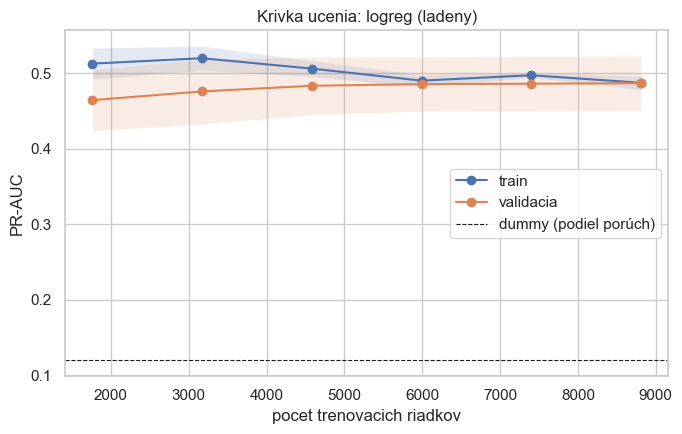

In [34]:
sizes, tr_s, va_s = learning_curve(final_pipe, train_X, train_y, groups=train_groups, cv=cv,
                                   train_sizes=np.linspace(0.2, 1.0, 6), scoring="average_precision", n_jobs=-1)
plt.figure(figsize=(7, 4.5))
for s_, lab in [(tr_s, "train"), (va_s, "validacia")]:
    plt.plot(sizes, s_.mean(axis=1), marker="o", label=lab)
    plt.fill_between(sizes, s_.mean(axis=1) - s_.std(axis=1), s_.mean(axis=1) + s_.std(axis=1), alpha=0.15)
plt.axhline(train_y.mean(), color="k", ls="--", lw=0.8, label="dummy (podiel porúch)")
plt.xlabel("pocet trenovacich riadkov"); plt.ylabel("PR-AUC"); plt.title(f"Krivka ucenia: {FINAL_NAME}")
plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
final_pipe.fit(train_X, train_y)
test_final = metriky(final_pipe, test_X, test_y)

proba = final_pipe.predict_proba(test_X)[:, 1]
d = pd.DataFrame({"u": test_groups.values, "y": test_y.values, "p": proba})
skupiny = {u: g for u, g in d.groupby("u")}
rng = np.random.default_rng(RANDOM_STATE)
units = np.array(list(skupiny))
boot = []
for _ in range(500):
    b = pd.concat([skupiny[u] for u in rng.choice(units, len(units))])
    boot.append(average_precision_score(b["y"], b["p"]))
lo, hi = np.percentile(boot, [2.5, 97.5])

print(test_final.round(3).to_string())
print(f"\ntest PR-AUC {test_final['PR-AUC']:.3f}, 95% interval (bootstrap po jednotkach) [{lo:.3f}, {hi:.3f}]")
print(f"CV PR-AUC (opakovana) {opak['PR-AUC val'].mean():.3f} +- {opak['PR-AUC val'].std():.3f}")

accuracy             0.765
balanced accuracy    0.755
precision            0.301
recall               0.743
F1                   0.429
ROC-AUC              0.837
PR-AUC               0.520

test PR-AUC 0.520, 95% interval (bootstrap po jednotkach) [0.460, 0.582]
CV PR-AUC (opakovana) 0.485 +- 0.001


In [43]:
modely = {"ID3 upraveny": id3_final, "Random Forest": final_forest, "Logisticka regresia": final_logreg}
gap = pd.DataFrame({n: ( cv_vysledky(m)["validacia"]) for n, m in modely.items()})
display(gap.loc[["accuracy", "balanced accuracy", "F1", "ROC-AUC", "PR-AUC"]].round(3))

,ID3 upraveny,Random Forest,Logisticka regresia
accuracy,0.725,0.845,0.764
balanced accuracy,0.697,0.716,0.735
F1,0.365,0.458,0.415
ROC-AUC,0.760,0.795,0.807
PR-AUC,0.364,0.451,0.487


## 3.4 Vyhodnotenie vplyvu zvolenej stratégie riešenia

Každú stratégiu hodnotíme experimentom z odstraňovaním: menia sa vždy jeden krok pipeline a porovnáva sa PR-AUC v tej istej 5-násobnej krížovej validácii delenej podľa `id_unit`. Rozhodujeme podľa rozdielu po foldoch (priemer rozdielu, jeho smerodajná odchýlka a počet foldov, v ktorých je variant lepší), nie podľa priemerov, lebo smerodajná odchýlka PR-AUC medzi foldami (0,036) je väčšia než väčšina rozdielov. Stratégiu považujeme za účinnú, len ak je rozdiel jasne väčší než jeho smerodajná odchýlka a platí vo všetkých alebo takmer všetkých foldoch.

### 3.4A Stratégie predspracovania

**Zachovanie informácie o chýbaní hodnôt.** Chýbajúce hodnoty v `dp_filter` a `rms_vibration` sme doplnili mediánom a zároveň zachovali príznaky `dp_filter_missing` a `rms_vibration_missing`. Vynechanie príznakov zníži PR-AUC logistickej regresie z 0,486 na 0,335 (−0,151, horšie v 5/5 foldov) a boostingu z 0,477 na 0,464 (−0,013, horšie v 5/5 foldov). Zachovanie príznakov je teda najúčinnejšia stratégia predspracovania na tomto datasete. Boosting stratí menej, pretože doplnená hodnota je konštanta, ktorú strom dokáže rozpoznať; lineárny model to nedokáže. Príznaky predpokladajú, že hodnota chýba pred poruchou, čo z dát nevieme overiť.

**Spôsob doplnenia a orezanie outlierov.** Medián, priemer a KNN imputácia a orezanie IQR, winsorizácia 1/99 alebo žiadne orezanie sa líšia o menej než 0,002 PR-AUC (smerodajná odchýlka medzi foldami je 0,036). Na tomto datasete sú rovnocenné, pretože chýbajúce hodnoty sú len v piatich stĺpcoch a ich informáciu nesú príznaky. Ponechali sme najjednoduchší variant (IQR, medián).

**Atribút `id_deport`.** Vynechanie atribútu nezmení výkon (+0,0001 PR-AUC pri oboch modeloch), preto ho z finálneho modelu odstraňujeme: zjednodušuje pipeline a odstraňuje `TargetEncoder`, ktorý nie je skupinový podľa `id_unit`. Asociácia depa s poruchou (χ² a permutačný test) sa teda nepremieta do prediktívneho prínosu.

### 3.4B Dátová transformácia

Experiment z odstraňovaním menil vždy jeden krok pipeline a porovnával PR-AUC na tých istých foldoch (hodnotíme rozdiel po foldoch).

| Krok | logistická regresia | boosting |
|---|---|---|
| Yeo-Johnson + StandardScaler (základ) | 0,486 | 0,477 |
| Quantile Transformer | 0,475 (−0,012, 0/5 foldov lepších) | 0,477 (±0,000) |
| bez transformácie (len scaler) | 0,484 (−0,002) | 0,477 (±0,000) |
| RobustScaler | 0,486 (−0,000) | 0,477 (±0,000) |
| bez škálovania | 0,484 (−0,002) | 0,477 (±0,000) |

Pre boosting sú transformácie a škálovanie neúčinné (presne rovnaké skóre), čo je očakávané: stromy závisia len od poradia hodnôt. Pre logistickú regresiu sú výsledky v rámci šumu okrem Quantile Transformeru, ktorý je mierne horší. Škálovanie `y_commission` (+0,0007) nie je preukázané (lepšie v 4/5 foldov, priemerný rozdiel len ~1,6-násobok svojej smerodajnej odchýlky), preto ho nepoužívame.

In [50]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import QuantileTransformer, RobustScaler

class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lo=0.01, hi=0.99):
        self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.nanquantile(X, self.lo, axis=0), np.nanquantile(X, self.hi, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)

def build_pipeline_v(outlier="iqr", impute="median", transform="yeo", scale="standard",
                     year_scaled=False, vyber=selected_final):
    out = {"iqr": OutlierClipper(), "winsor": QuantileClipper(0.01, 0.99), "none": "passthrough"}[outlier]
    imp = {"median": SimpleImputer(strategy="median"), "mean": SimpleImputer(strategy="mean"),
           "knn": KNNImputer(n_neighbors=5)}[impute]
    tr = {"yeo": PowerTransformer(method="yeo-johnson", standardize=False),
          "quantile": QuantileTransformer(output_distribution="normal", n_quantiles=200,
                                          random_state=RANDOM_STATE),
          "none": "passthrough"}[transform]
    sc = {"standard": StandardScaler(), "robust": RobustScaler(), "none": "passthrough"}[scale]
    cols = spojite + (["y_commission"] if year_scaled else [])
    continuous = Pipeline([("clip", out), ("impute", imp), ("transform", tr), ("scale", sc)])
    ct = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.05,
                                 sparse_output=False), CAT_COLS),
        ("depot", TargetEncoder(target_type="binary", smooth="auto", cv=5, shuffle=True,
                                random_state=RANDOM_STATE), ["id_deport"]),
        ("continuous", continuous, cols),
    ], remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("transform", ct), ("select", ColumnSelector(vyber))]).set_output(transform="pandas")

In [51]:
from sklearn.model_selection import cross_val_score

def pr_auc_folds(prep, model):
    pipe = Pipeline([("prep", prep), ("model", model)])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return cross_val_score(pipe, train_X, train_y, groups=train_groups, cv=cv,
                               scoring="average_precision", n_jobs=-1)

lr_final = LogisticRegression(C=1, class_weight="balanced", max_iter=3000)
varianty = {
    "zaklad (iqr, median, yeo, standard)": {},
    "bez orezania outlierov":              {"outlier": "none"},
    "winsorizacia 1/99":                   {"outlier": "winsor"},
    "imputacia priemerom":                 {"impute": "mean"},
    "imputacia KNN":                       {"impute": "knn"},
    "quantile transformer":                {"transform": "quantile"},
    "bez transformacie (len scaler)":      {"transform": "none"},
    "RobustScaler":                        {"scale": "robust"},
    "bez skalovania":                      {"transform": "none", "scale": "none"},
    "y_commission skalovany":              {"year_scaled": True},
}
zaklad = pr_auc_folds(build_pipeline_v(), lr_final)
riadky = []
for nazov, kw in varianty.items():
    s = zaklad if not kw else pr_auc_folds(build_pipeline_v(**kw), lr_final)
    d = s - zaklad
    riadky.append({"variant": nazov, "PR-AUC val": s.mean(), "rozdiel oproti zakladu": d.mean(),
                   "std rozdielu (po foldoch)": d.std(), "foldy lepsie": int((d > 0).sum())})
abl = pd.DataFrame(riadky).set_index("variant")
display(abl.round(4))

,PR-AUC val,rozdiel oproti zakladu,std rozdielu (po foldoch),foldy lepsie
variant,,,,
"zaklad (iqr, median, yeo, standard)",0.4860,0.0000,0.0000,0
bez orezania outlierov,0.4864,0.0004,0.0025,3
winsorizacia 1/99,0.4853,-0.0007,0.0016,2
imputacia priemerom,0.4860,-0.0000,0.0003,3
imputacia KNN,0.4842,-0.0018,0.0024,2
quantile transformer,0.4745,-0.0115,0.0088,0
bez transformacie (len scaler),0.4841,-0.0018,0.0034,1
RobustScaler,0.4859,-0.0001,0.0001,1
bez skalovania,0.4837,-0.0023,0.0049,1


In [52]:
hgb_final = HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                           random_state=RANDOM_STATE,
                                           **strip(NAJLEPSIE["hist gradient boosting"]))

def ablacia(model, varianty):
    zaklad = pr_auc_folds(build_pipeline_v(), model)
    riadky = []
    for nazov, kw in varianty.items():
        s = pr_auc_folds(build_pipeline_v(**kw), model)
        d = s - zaklad
        riadky.append({"variant": nazov, "PR-AUC val": s.mean(), "rozdiel": d.mean(),
                       "std rozdielu": d.std(), "foldy lepsie": int((d > 0).sum())})
    return pd.DataFrame(riadky).set_index("variant")

bez_missing = [c for c in selected_final if not c.endswith("_missing")]
bez_depa    = [c for c in selected_final if c != "id_deport"]

prep_var = {k: v for k, v in varianty.items() if v}
display(ablacia(hgb_final, prep_var).round(4))

atr_var = {"bez *_missing": {"vyber": bez_missing}, "bez id_deport": {"vyber": bez_depa},
           "bez oboch": {"vyber": [c for c in bez_missing if c != "id_deport"]}}
for n, m in [("logreg", lr_final), ("boosting", hgb_final)]:
    print(n); display(ablacia(m, atr_var).round(4))

,PR-AUC val,rozdiel,std rozdielu,foldy lepsie
variant,,,,
bez orezania outlierov,0.4760,-0.0008,0.0022,2
winsorizacia 1/99,0.4760,-0.0008,0.0022,2
imputacia priemerom,0.4764,-0.0005,0.0030,3
imputacia KNN,0.4754,-0.0014,0.0028,2
quantile transformer,0.4768,0.0000,0.0000,0
bez transformacie (len scaler),0.4768,0.0000,0.0000,0
RobustScaler,0.4768,0.0000,0.0000,0
bez skalovania,0.4768,0.0000,0.0000,0
y_commission skalovany,0.4773,0.0005,0.0012,2


logreg


,PR-AUC val,rozdiel,std rozdielu,foldy lepsie
variant,,,,
bez *_missing,0.3351,-0.1509,0.0169,0
bez id_deport,0.4861,0.0001,0.0001,4
bez oboch,0.3348,-0.1512,0.0167,0


boosting


,PR-AUC val,rozdiel,std rozdielu,foldy lepsie
variant,,,,
bez *_missing,0.4642,-0.0126,0.0060,0
bez id_deport,0.4769,0.0001,0.0014,2
bez oboch,0.4650,-0.0119,0.0058,0


### Výber atribútov

Porovnávame všetky atribúty po predspracovaní so zoznamom z 2.2 (zoradeným podľa dôležitosti) a s jeho najlepšími k atribútmi. Výber robíme len na trénovacej množine, ale zoznam bol zostavený na celej trénovacej množine a nie v každom folde zvlášť, takže mierne nadsadzuje výkon vybraných atribútov (pri ablácii nižšie to platí pre všetky varianty rovnako).

In [44]:
vsetky = build_pipeline(vyber=None).fit_transform(train_X, train_y).columns.tolist()
print("pocet atributov po predspracovani:", len(vsetky))

var_atr = {f"vsetky ({len(vsetky)})": {"vyber": vsetky},
           "top 10": {"vyber": selected_final[:10]},
           "top 8": {"vyber": selected_final[:8]},
           "top 5": {"vyber": selected_final[:5]},
           "top 3": {"vyber": selected_final[:3]}}
for n, m in [("logreg", lr_final), ("boosting", hgb_final)]:
    print(n, "(zaklad = 16 atributov z 2.2)")
    display(ablacia(m, var_atr).round(4))

pocet atributov po predspracovani: 31
logreg (zaklad = 16 atributov z 2.2)


,PR-AUC val,rozdiel,std rozdielu,foldy lepsie
variant,,,,
vsetky (31),0.4797,-0.0063,0.0050,1
top 10,0.4853,-0.0007,0.0024,3
top 8,0.4705,-0.0155,0.0048,0
top 5,0.4277,-0.0583,0.0101,0
top 3,0.3215,-0.1645,0.0159,0


boosting (zaklad = 16 atributov z 2.2)


,PR-AUC val,rozdiel,std rozdielu,foldy lepsie
variant,,,,
vsetky (31),0.4726,-0.0042,0.0037,0
top 10,0.4717,-0.0051,0.0070,1
top 8,0.4602,-0.0167,0.0060,0
top 5,0.4205,-0.0563,0.0080,0
top 3,0.3208,-0.1561,0.0152,0


Po predspracovaní je 31 atribútov; ponechávame 15 vybraných v 2.2. Logistická regresia s 31 atribútmi má PR-AUC 0,480 oproti 0,486 pri 16 atribútoch (−0,006 ± 0,005, lepšia v 1 z 5 foldov), boosting 0,473 oproti 0,477 (−0,004, 0/5 foldov). Výber teda výkon nezhoršil, ale ani výrazne nezlepšil; jeho prínosom je jednoduchší model s polovicou atribútov. Prvých 10 atribútov je rovnocenných (0,485; −0,001), atribúty 11 až 16 nepridávajú nič. Pod 10 výkon klesá: top 8 −0,016, top 5 −0,058, top 3 −0,165 (v žiadnom folde lepšie). Samotné tri najdôležitejšie atribúty (príznaky chýbania a `duty_class`) dosahujú PR-AUC 0,322, čo je asi 55 % prírastku nad náhodným odhadom (0,120 → 0,486). Poradie z 2.2 sme zostavili na celej trénovacej množine, nie vnorene, takže pri vybraných atribútoch môže byť výkon mierne nadsadený; porovnanie s 31 atribútmi preto nepovažujeme za pevný dôkaz prínosu výberu.

### Výber metrík

Porovnáme poradie modelov podľa accuracy a podľa metrík vhodných pre nevyváženú triedu. Model `dummy`, ktorý vždy predikuje „bez poruchy“, slúži ako dôkaz, že accuracy je pri 12 % porúch zavádzajúca.

In [45]:
podmnozina = {"dummy (vzdy bez poruchy)": sk_pipeline(DummyClassifier(strategy="most_frequent")),
              "ID3 cisty": id3_pipeline(), "ID3 upraveny": id3_pipeline(**PARAMS),
              "random forest (3.2)": final_forest, "logreg": final_logreg}
met = pd.DataFrame({n: cv_vysledky(p)["validacia"] for n, p in podmnozina.items()}).T[
    ["accuracy", "balanced accuracy", "recall", "precision", "F1", "ROC-AUC", "PR-AUC"]]
display(met.round(3))
display(met.rank(ascending=False).astype(int).rename(columns=lambda c: c + " (poradie)"))

,accuracy,balanced accuracy,recall,precision,F1,ROC-AUC,PR-AUC
dummy (vzdy bez poruchy),0.880,0.500,0.000,0.000,0.000,0.500,0.120
ID3 cisty,0.820,0.593,0.295,0.270,0.282,0.609,0.172
ID3 upraveny,0.725,0.697,0.659,0.253,0.365,0.760,0.364
random forest (3.2),0.845,0.716,0.548,0.395,0.458,0.795,0.451
logreg,0.764,0.735,0.699,0.296,0.415,0.807,0.487


,accuracy (poradie),balanced accuracy (poradie),recall (poradie),precision (poradie),F1 (poradie),ROC-AUC (poradie),PR-AUC (poradie)
dummy (vzdy bez poruchy),1,5,5,5,5,5,5
ID3 cisty,3,4,4,3,4,4,4
ID3 upraveny,5,3,2,4,3,3,3
random forest (3.2),2,2,3,1,1,2,2
logreg,4,1,1,2,2,1,1


Podľa accuracy je najlepší model „vždy bez poruchy“ (0,880), ktorý nezachytí žiadnu poruchu (recall 0), a najhorší upravený ID3 (0,725), ktorý ich zachytí 66 %. Accuracy preto nepoužívame na výber. Podľa prahovo nezávislých metrík je najlepšia logistická regresia (ROC-AUC 0,807, PR-AUC 0,487). Podľa F1 pri prahu 0,5 je lepší Random Forest z 3.2 (0,458 oproti 0,415), ale ten má rozdiel train − validácia 0,199 PR-AUC (overfit) a nižšie PR-AUC (0,451); F1 pri jedinom prahu navyše mení poradie podľa prahu, preto rozhodujeme podľa PR-AUC.

### Algoritmy, ladenie a ensemble

Prírastok každého kroku meriame párovým porovnaním po foldoch voči finálnemu modelu (logistická regresia po ladení). Krok sa považuje za prínosný, ak je rozdiel jasne nad smerodajnou odchýlkou rozdielu.

,PR-AUC,rozdiel vs logreg,std rozdielu,foldy lepsie ako logreg
logreg (3.2),0.4870,0.0000,0.0000,0.0
logreg (ladeny),0.4870,0.0000,0.0000,0.0
voting (LR + RF + HGB),0.4823,-0.0046,0.0053,2.0
hist gradient boosting,0.4768,-0.0101,0.0027,0.0
random forest (3.2),0.4506,-0.0363,0.0084,0.0
random forest (ladeny),0.4472,-0.0398,0.0144,0.0
ID3 upraveny,0.3644,-0.1225,0.0124,0.0
dummy (prior),0.1198,-0.3671,0.0358,0.0


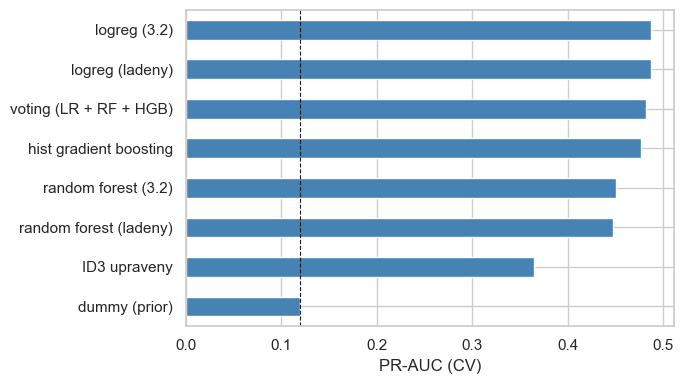

In [46]:
def folds(pipe):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return cross_val_score(pipe, train_X, train_y, groups=train_groups, cv=cv,
                               scoring="average_precision", n_jobs=-1)

fs = {n: folds(p) for n, p in kandidati.items()}
ref = fs["logreg (ladeny)"]
par = pd.DataFrame({n: {"PR-AUC": s.mean(), "rozdiel vs logreg": (s - ref).mean(),
                        "std rozdielu": (s - ref).std(), "foldy lepsie ako logreg": int((s > ref).sum())}
                    for n, s in fs.items()}).T
display(par.sort_values("PR-AUC", ascending=False).round(4))

par["PR-AUC"].sort_values().plot.barh(figsize=(7, 4), color="steelblue")
plt.axvline(train_y.mean(), color="k", ls="--", lw=0.8); plt.xlabel("PR-AUC (CV)")
plt.tight_layout(); plt.show()

 Neobmedzené stromy overfitujú (ID3: rozdiel train − validácia 0,707 PR-AUC, les 0,199); obmedzenie zložitosti rozdiel zníži (ID3 0,016, ladený les 0,045), ladený les však stratil 0,004 PR-AUC. Ladenie logistickej regresie nezmenilo nič. Oproti logistickej regresii je boosting horší (−0,010 ± 0,003, 0/5 foldov lepších), hlasovanie nerozoznateľné (−0,005 ± 0,005, 2/5) a les horší (−0,036; ladený −0,040). Ensemble teda výkon nezvyšuje a pridáva zložitosť, takže ho do nasadenia nezaraďujeme. Rozdiely sú počítané z piatich navzájom prekrývajúcich sa foldov, takže ich berieme ako orientačné.

In [47]:
lr_params = strip(NAJLEPSIE["logreg"])
FINAL_FEATURES = [c for c in selected_final if c != "id_deport"]
final_model = Pipeline([("prep", build_pipeline_v(vyber=FINAL_FEATURES)),
                        ("model", LogisticRegression(class_weight="balanced", max_iter=3000, **lr_params))])

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import fbeta_score
oof = cross_val_predict(final_model, train_X, train_y, groups=train_groups, cv=cv,
                        method="predict_proba", n_jobs=-1)[:, 1]
riadky = []
for t in np.arange(0.30, 0.86, 0.05):
    p = (oof >= t).astype(int)
    riadky.append({"prah": round(t, 2), "recall": recall_score(train_y, p),
                   "precision": precision_score(train_y, p, zero_division=0),
                   "F1": f1_score(train_y, p), "F2": fbeta_score(train_y, p, beta=2),
                   "hlaseni na 100 cyklov": 100 * p.mean()})
prahy = pd.DataFrame(riadky).set_index("prah")
display(prahy.round(3))
THRESHOLD = float(prahy["F2"].idxmax())
print("vybrany prah (max F2):", THRESHOLD)

,recall,precision,F1,F2,hlaseni na 100 cyklov
prah,,,,,
0.30,0.892,0.178,0.296,0.494,60.176
0.35,0.859,0.200,0.324,0.518,51.525
0.40,0.812,0.227,0.355,0.536,42.810
0.45,0.758,0.258,0.385,0.546,35.167
0.50,0.698,0.295,0.414,0.548,28.413
0.55,0.641,0.344,0.448,0.547,22.295
0.60,0.584,0.395,0.472,0.533,17.702
0.65,0.512,0.446,0.477,0.497,13.744
0.70,0.439,0.494,0.465,0.449,10.657


vybrany prah (max F2): 0.5


**Prah rozhodovania.** Prah sme volili na out-of-fold predikciách trénovacej CV podľa F2, ktoré dáva väčšiu váhu recallu; predpokladáme, že prehliadnutá porucha je drahšia než falošný poplach (platí len ak to potvrdí údržba). F2 je v rozsahu 0,45 až 0,55 takmer rovnaké (0,546 až 0,548), maximum je pri 0,50. Pri tomto prahu model hlási asi 28 cyklov zo 100 (recall 0,70, precision 0,30), teda pri 12 skutočných poruchách asi 8 zachytí a 20 hlásení je falošných. Kto potrebuje menej falošných poplachov, dostane napríklad pri prahu 0,70 precision 0,49 za cenu recallu 0,44.

### 3.4D Najlepší model pre nasadenie

Pre nasadenie volíme **logistickú regresiu s 15 atribútmi bez `id_deport`**.

* Má najvyššie validačné PR-AUC (0,487) a najmenší rozdiel train − validácia (0,001), čo je overfit vylúčený; zložitejšie modely (boosting, les, hlasovanie) ho nepredčia.
* Nie je underfit: je 4× nad modelom `dummy` (PR-AUC 0,12).
* Je stabilná: PR-AUC pri piatich rôznych delenia je 0,485 ± 0,001.
* Je najjednoduchšia a najrýchlejšia na vyhodnotenie, jej koeficienty sa dajú vysvetliť a nepotrebuje `TargetEncoder`.
* `id_deport` sme odstránili, lebo jeho vynechanie nezmenilo výkon (+0,0001 PR-AUC).

CV PR-AUC finalneho modelu: 0.4869 +- 0.0358   (s id_deport: 0.4870)
accuracy             0.765
balanced accuracy    0.756
precision            0.301
recall               0.743
F1                   0.429
ROC-AUC              0.837
PR-AUC               0.520
test PR-AUC 95% interval (bootstrap po jednotkach): [0.46  0.582]


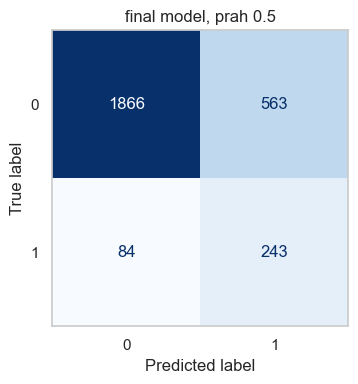

In [48]:
s_cv = folds(final_model)
print(f"CV PR-AUC finalneho modelu: {s_cv.mean():.4f} +- {s_cv.std():.4f}   (s id_deport: {ref.mean():.4f})")

final_model.fit(train_X, train_y)
proba_t = final_model.predict_proba(test_X)[:, 1]
pred_t = (proba_t >= THRESHOLD).astype(int)
test_vys = pd.Series({"accuracy": accuracy_score(test_y, pred_t), "balanced accuracy": balanced_accuracy_score(test_y, pred_t),
                      "precision": precision_score(test_y, pred_t), "recall": recall_score(test_y, pred_t),
                      "F1": f1_score(test_y, pred_t), "ROC-AUC": roc_auc_score(test_y, proba_t),
                      "PR-AUC": average_precision_score(test_y, proba_t)})
print(test_vys.round(3).to_string())

d = pd.DataFrame({"u": test_groups.values, "y": test_y.values, "p": proba_t})
sk = {u: g for u, g in d.groupby("u")}; units = np.array(list(sk)); rng = np.random.default_rng(RANDOM_STATE)
boot = [average_precision_score(*(lambda b: (b["y"], b["p"]))(pd.concat([sk[u] for u in rng.choice(units, len(units))])))
        for _ in range(500)]
print("test PR-AUC 95% interval (bootstrap po jednotkach):", np.percentile(boot, [2.5, 97.5]).round(3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(test_y, pred_t, ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"final model, prah {THRESHOLD}"); ax.grid(False); plt.tight_layout(); plt.show()

In [49]:
def build_pipeline_prod():
    continuous = Pipeline([("clip", OutlierClipper()), ("impute", SimpleImputer(strategy="median")),
                           ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
                           ("scale", StandardScaler())])
    ct = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.05,
                                 sparse_output=False), CAT_COLS),
        ("continuous", continuous, spojite)], remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("transform", ct), ("select", ColumnSelector(FINAL_FEATURES))]).set_output(transform="pandas")

prod_model = Pipeline([("prep", build_pipeline_prod()),
                       ("model", LogisticRegression(class_weight="balanced", max_iter=3000, **lr_params))])
s_prod = folds(prod_model)
print(f"CV PR-AUC produkcnej pipeline: {s_prod.mean():.4f} (rozdiel oproti final_model: {(s_prod - s_cv).mean():+.4f})")
prod_model.fit(train_X, train_y)
assert np.allclose(prod_model.predict_proba(test_X)[:, 1], proba_t), "produkcna pipeline sa lisi od final_model"

CV PR-AUC produkcnej pipeline: 0.4869 (rozdiel oproti final_model: +0.0000)


### Dátová pipeline v produkcii

1. **Vstup:** surové merania (`id_unit`, `cycle_ts`, 7 senzorov), bez cieľa.
2. **Čistenie** (`clean_readings`): oprava `id_unit` (odpočítanie 90 000, odstránenie prefixu `U`), parsovanie dátumov, chybové kódy senzorov (−999, 99, 120) na `NaN`, zlúčenie duplicít (jednotka + čas).
3. **Pripojenie hlavných dát:** `units_lookup` a `gateways_lookup` (uložené z vývoja), kontrola `validate="m:1"` a nezmeneného počtu riadkov.
4. **Odvodené atribúty:** dni od inštalácie a od overhaulu, mesiac, príznaky `*_missing`, `seen_before_install`.
5. **Sklearn pipeline:** orezanie outlierov (1,5 × IQR) → medián → Yeo-Johnson → StandardScaler → one-hot → výber 15 atribútov → logistická regresia. Všetky parametre sú naučené na trénovacej množine a uložené v `failure_model.joblib`.
6. **Výstup:** riziko poruchy a alert pri prahu z metadát.
7. **Monitorovanie:** podiel chýbajúcich `dp_filter` a `rms_vibration` (v tréningu 3,7 % a 3,9 %), rozdelenie senzorov oproti `reference_feature_stats`, podiel alertov a podiel jednotiek mimo lookup tabuliek. Pri výraznej zmene sa model pretrénuje.

Pri nasadení musia byť rovnaké verzie knižníc ako v `model_metadata.json`. Triedy `OutlierClipper` a `ColumnSelector` a funkcie `clean_*` a `make_numeric_frame` musia byť dostupné v importovateľnom module (nie len v notebooku), inak sa `joblib.load` mimo notebooku nepodarí.

In [53]:
import joblib, json, os, sys, platform, datetime, sklearn
os.makedirs("./model/lookups", exist_ok=True)
joblib.dump(prod_model, "./model/failure_model.joblib")
units_c.to_csv("./model/lookups/units_lookup.csv", index=False)
gateways_c.to_csv("./model/lookups/gateways_lookup.csv", index=False)

ref_stats = train_X[spojite].describe().T[["mean", "std", "min", "50%", "max"]].round(4).to_dict("index")
meta = {
    "model": "LogisticRegression (class_weight=balanced) + preprocessing pipeline",
    "trained_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
    "random_state": RANDOM_STATE,
    "hyperparameters": {"C": lr_params.get("C"), "class_weight": "balanced"},
    "training_data": {"rows": int(len(train_X)), "units": int(train_groups.nunique()),
                      "fail_rate": round(float(train_y.mean()), 4)},
    "raw_input": {"file": "readings (tab-separated)",
                  "columns": ["id_unit (napr. U00078)", "cycle_ts", "currentMotor", "dp_filter", "oilTemperature",
                              "pressure_reservoir", "rmsVibration", "Flowmeter", "dischargeDewpoint"],
                  "target_column_required": False},
    "lookup_tables": ["lookups/units_lookup.csv", "lookups/gateways_lookup.csv"],
    "model_input_columns": list(train_X.columns),
    "selected_features": FINAL_FEATURES,
    "decision_threshold": THRESHOLD,
    "threshold_rationale": "max F2 na out-of-fold predikciach trenovacej CV; predpoklad: prehliadnuta porucha je drahsia nez falosny poplach",
    "metrics": {"cv_PR_AUC_mean": round(float(s_prod.mean()), 4), "cv_PR_AUC_std_folds": round(float(s_prod.std()), 4),
                "test": {k: round(float(v), 4) for k, v in test_vys.items()}},
    "reference_feature_stats": ref_stats,
    "reference_missing_rate": {c: round(float(train_X[c].mean()), 4) for c in ["dp_filter_missing", "rms_vibration_missing"]},
    "known_limitations": [
        "priznaky *_missing predpokladaju, ze hodnota chyba pred poruchou (z dat neoverene)",
        "jednotka mimo lookup tabuliek dostane median namiesto vlastnych atributov",
        "precision okolo 0,3: dve z troch hlaseni su falosne poplachy"],
}
json.dump(meta, open("./model/model_metadata.json", "w"), indent=2, ensure_ascii=False)

In [54]:
def predict_from_raw(readings_raw, model, threshold):
    raw = readings_raw.copy()
    if "Failure" not in raw.columns:
        raw["Failure"] = 0
    kluce = clean_readings(raw)[["id_unit", "cycle_ts"]].reset_index(drop=True)
    X = make_numeric_frame(raw).drop(columns=["fail", "id_unit"])
    p = model.predict_proba(X)[:, 1]
    return kluce.assign(riziko=p, alert=(p >= threshold).astype(int))

loaded = joblib.load("./model/failure_model.joblib")
vystup = predict_from_raw(data.iloc[test_idx].drop(columns="Failure"), loaded, THRESHOLD)
assert np.allclose(vystup["riziko"], proba_t), "nacitany model dava ine predikcie"
print(vystup.head(), "| alertov:", int(vystup["alert"].sum()), "z", len(vystup))

   id_unit            cycle_ts    riziko  alert
0        2 2023-02-17 14:29:00  0.154051      0
1        2 2023-06-09 00:00:00  0.120944      0
2        2 2023-09-12 00:00:00  0.078188      0
3        5 2023-03-11 00:00:00  0.455696      0
4        5 2023-04-14 13:57:00  0.225758      0 | alertov: 806 z 2756
